# Projeto AM-NS — Equipe 08
## Agrupamento, redução de dimensionalidade e artigo IEEE

Este notebook reúne **todo o código Python do projeto**: sete agrupamentos, quatro projeções, exploração original de K-Means, auditoria, geração do relatório detalhado e do artigo IEEE. Não importa nem executa os arquivos `.py` externos.

A única fonte dos requisitos é **Projeto-AMG-NS-2026-2.pdf**, para a **Equipe 08**. Os dados Iris usados nos experimentos estão incorporados abaixo, sem necessidade de download.

**Como usar:** selecione um kernel Python com as dependências instaladas e execute as células de cima para baixo (*Restart Kernel and Run All*). As saídas ficam em `execucao_notebook/`, preservando os resultados anteriores. Os 252 ajustes e as quatro projeções são executados por padrão. A compilação dos PDFs requer Typst; se ele não estiver instalado, os fontes `.typ` continuam sendo gerados.

A célula de dependências é uma instrução de instalação, não instala pacotes automaticamente. A exploração histórica é opcional para não confundir seus ajustes adicionais com os 252 ajustes do protocolo. As análises textuais dos relatórios correspondem à configuração padrão; revise-as se mudar os parâmetros.

## 1. Ambiente e configuração

No terminal, instale `pip install -r requirements-notebook.txt`. No Jupyter, também é possível executar `%pip install -r requirements-notebook.txt`. O Python usado na execução original foi 3.14.

Versões científicas utilizadas:
```text
annotated-types==0.8.0
click==8.5.0
cloudpickle==3.1.2
contourpy==1.4.0
cycler==0.12.1
fonttools==4.67.0
fuzzy-c-means==2.3.1
joblib==1.6.0
kiwisolver==1.5.1
kmedoids==0.5.5
llvmlite==0.50.0
matplotlib==3.11.2
narwhals==2.27.1
numba==0.68.0
numpy==2.5.4
packaging==26.3
pandas==3.0.6
pillow==13.0.0
pydantic==2.14.1
pydantic_core==2.50.1
pynndescent==0.6.0
pyparsing==3.3.3
python-dateutil==2.9.0.post0
scikit-learn==1.9.1
scikit-learn-extra==0.3.0
scipy==1.18.1
seaborn==0.13.2
six==1.17.0
tabulate==0.10.0
threadpoolctl==3.7.0
tqdm==4.70.1
typer==0.9.4
typing-inspection==0.4.4
typing_extensions==4.16.0
umap-learn==0.5.12
```

In [1]:
from pathlib import Path
import os
import tempfile
import json
import base64

# Configure antes de importar NumPy, Matplotlib ou UMAP.
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "matplotlib-iris-notebook"))
for variavel in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "NUMBA_NUM_THREADS"):
    os.environ.setdefault(variavel, "1")

BASE = Path.cwd() / "execucao_notebook"
BASE.mkdir(parents=True, exist_ok=True)
EXECUTAR_EXPLORACAO = False
GERAR_DOCUMENTOS = True
COMPILAR_PDFS = True
print(f"Diretório dos artefatos: {BASE}")

# Exibição no Jupyter e execução alternativa em Python sem IPython.
def mostrar(valor):
    if "_registrar_saida" in globals():
        dados = {"text/plain": str(valor)}
        if hasattr(valor, "_repr_html_"):
            dados["text/html"] = valor._repr_html_()
        _registrar_saida(dados)
    else:
        try:
            from IPython.display import display
            display(valor)
        except ImportError:
            print(valor)

def mostrar_imagem(caminho):
    dados = {"image/png": base64.b64encode(Path(caminho).read_bytes()).decode("ascii"),
             "text/plain": Path(caminho).name}
    if "_registrar_saida" in globals():
        _registrar_saida(dados)
    else:
        try:
            from IPython.display import display
            display(dados, raw=True)
        except ImportError:
            print(f"Figura salva: {caminho}")

Diretório dos artefatos: /home/araujo/Graduação/7º período/Aprendizado não Supervisionado/Projeto/execucao_notebook


In [2]:
# Cópia exata dos dados locais utilizados no projeto.
DADOS_IRIS = '5.1,3.5,1.4,0.2,Iris-setosa\n4.9,3.0,1.4,0.2,Iris-setosa\n4.7,3.2,1.3,0.2,Iris-setosa\n4.6,3.1,1.5,0.2,Iris-setosa\n5.0,3.6,1.4,0.2,Iris-setosa\n5.4,3.9,1.7,0.4,Iris-setosa\n4.6,3.4,1.4,0.3,Iris-setosa\n5.0,3.4,1.5,0.2,Iris-setosa\n4.4,2.9,1.4,0.2,Iris-setosa\n4.9,3.1,1.5,0.1,Iris-setosa\n5.4,3.7,1.5,0.2,Iris-setosa\n4.8,3.4,1.6,0.2,Iris-setosa\n4.8,3.0,1.4,0.1,Iris-setosa\n4.3,3.0,1.1,0.1,Iris-setosa\n5.8,4.0,1.2,0.2,Iris-setosa\n5.7,4.4,1.5,0.4,Iris-setosa\n5.4,3.9,1.3,0.4,Iris-setosa\n5.1,3.5,1.4,0.3,Iris-setosa\n5.7,3.8,1.7,0.3,Iris-setosa\n5.1,3.8,1.5,0.3,Iris-setosa\n5.4,3.4,1.7,0.2,Iris-setosa\n5.1,3.7,1.5,0.4,Iris-setosa\n4.6,3.6,1.0,0.2,Iris-setosa\n5.1,3.3,1.7,0.5,Iris-setosa\n4.8,3.4,1.9,0.2,Iris-setosa\n5.0,3.0,1.6,0.2,Iris-setosa\n5.0,3.4,1.6,0.4,Iris-setosa\n5.2,3.5,1.5,0.2,Iris-setosa\n5.2,3.4,1.4,0.2,Iris-setosa\n4.7,3.2,1.6,0.2,Iris-setosa\n4.8,3.1,1.6,0.2,Iris-setosa\n5.4,3.4,1.5,0.4,Iris-setosa\n5.2,4.1,1.5,0.1,Iris-setosa\n5.5,4.2,1.4,0.2,Iris-setosa\n4.9,3.1,1.5,0.1,Iris-setosa\n5.0,3.2,1.2,0.2,Iris-setosa\n5.5,3.5,1.3,0.2,Iris-setosa\n4.9,3.1,1.5,0.1,Iris-setosa\n4.4,3.0,1.3,0.2,Iris-setosa\n5.1,3.4,1.5,0.2,Iris-setosa\n5.0,3.5,1.3,0.3,Iris-setosa\n4.5,2.3,1.3,0.3,Iris-setosa\n4.4,3.2,1.3,0.2,Iris-setosa\n5.0,3.5,1.6,0.6,Iris-setosa\n5.1,3.8,1.9,0.4,Iris-setosa\n4.8,3.0,1.4,0.3,Iris-setosa\n5.1,3.8,1.6,0.2,Iris-setosa\n4.6,3.2,1.4,0.2,Iris-setosa\n5.3,3.7,1.5,0.2,Iris-setosa\n5.0,3.3,1.4,0.2,Iris-setosa\n7.0,3.2,4.7,1.4,Iris-versicolor\n6.4,3.2,4.5,1.5,Iris-versicolor\n6.9,3.1,4.9,1.5,Iris-versicolor\n5.5,2.3,4.0,1.3,Iris-versicolor\n6.5,2.8,4.6,1.5,Iris-versicolor\n5.7,2.8,4.5,1.3,Iris-versicolor\n6.3,3.3,4.7,1.6,Iris-versicolor\n4.9,2.4,3.3,1.0,Iris-versicolor\n6.6,2.9,4.6,1.3,Iris-versicolor\n5.2,2.7,3.9,1.4,Iris-versicolor\n5.0,2.0,3.5,1.0,Iris-versicolor\n5.9,3.0,4.2,1.5,Iris-versicolor\n6.0,2.2,4.0,1.0,Iris-versicolor\n6.1,2.9,4.7,1.4,Iris-versicolor\n5.6,2.9,3.6,1.3,Iris-versicolor\n6.7,3.1,4.4,1.4,Iris-versicolor\n5.6,3.0,4.5,1.5,Iris-versicolor\n5.8,2.7,4.1,1.0,Iris-versicolor\n6.2,2.2,4.5,1.5,Iris-versicolor\n5.6,2.5,3.9,1.1,Iris-versicolor\n5.9,3.2,4.8,1.8,Iris-versicolor\n6.1,2.8,4.0,1.3,Iris-versicolor\n6.3,2.5,4.9,1.5,Iris-versicolor\n6.1,2.8,4.7,1.2,Iris-versicolor\n6.4,2.9,4.3,1.3,Iris-versicolor\n6.6,3.0,4.4,1.4,Iris-versicolor\n6.8,2.8,4.8,1.4,Iris-versicolor\n6.7,3.0,5.0,1.7,Iris-versicolor\n6.0,2.9,4.5,1.5,Iris-versicolor\n5.7,2.6,3.5,1.0,Iris-versicolor\n5.5,2.4,3.8,1.1,Iris-versicolor\n5.5,2.4,3.7,1.0,Iris-versicolor\n5.8,2.7,3.9,1.2,Iris-versicolor\n6.0,2.7,5.1,1.6,Iris-versicolor\n5.4,3.0,4.5,1.5,Iris-versicolor\n6.0,3.4,4.5,1.6,Iris-versicolor\n6.7,3.1,4.7,1.5,Iris-versicolor\n6.3,2.3,4.4,1.3,Iris-versicolor\n5.6,3.0,4.1,1.3,Iris-versicolor\n5.5,2.5,4.0,1.3,Iris-versicolor\n5.5,2.6,4.4,1.2,Iris-versicolor\n6.1,3.0,4.6,1.4,Iris-versicolor\n5.8,2.6,4.0,1.2,Iris-versicolor\n5.0,2.3,3.3,1.0,Iris-versicolor\n5.6,2.7,4.2,1.3,Iris-versicolor\n5.7,3.0,4.2,1.2,Iris-versicolor\n5.7,2.9,4.2,1.3,Iris-versicolor\n6.2,2.9,4.3,1.3,Iris-versicolor\n5.1,2.5,3.0,1.1,Iris-versicolor\n5.7,2.8,4.1,1.3,Iris-versicolor\n6.3,3.3,6.0,2.5,Iris-virginica\n5.8,2.7,5.1,1.9,Iris-virginica\n7.1,3.0,5.9,2.1,Iris-virginica\n6.3,2.9,5.6,1.8,Iris-virginica\n6.5,3.0,5.8,2.2,Iris-virginica\n7.6,3.0,6.6,2.1,Iris-virginica\n4.9,2.5,4.5,1.7,Iris-virginica\n7.3,2.9,6.3,1.8,Iris-virginica\n6.7,2.5,5.8,1.8,Iris-virginica\n7.2,3.6,6.1,2.5,Iris-virginica\n6.5,3.2,5.1,2.0,Iris-virginica\n6.4,2.7,5.3,1.9,Iris-virginica\n6.8,3.0,5.5,2.1,Iris-virginica\n5.7,2.5,5.0,2.0,Iris-virginica\n5.8,2.8,5.1,2.4,Iris-virginica\n6.4,3.2,5.3,2.3,Iris-virginica\n6.5,3.0,5.5,1.8,Iris-virginica\n7.7,3.8,6.7,2.2,Iris-virginica\n7.7,2.6,6.9,2.3,Iris-virginica\n6.0,2.2,5.0,1.5,Iris-virginica\n6.9,3.2,5.7,2.3,Iris-virginica\n5.6,2.8,4.9,2.0,Iris-virginica\n7.7,2.8,6.7,2.0,Iris-virginica\n6.3,2.7,4.9,1.8,Iris-virginica\n6.7,3.3,5.7,2.1,Iris-virginica\n7.2,3.2,6.0,1.8,Iris-virginica\n6.2,2.8,4.8,1.8,Iris-virginica\n6.1,3.0,4.9,1.8,Iris-virginica\n6.4,2.8,5.6,2.1,Iris-virginica\n7.2,3.0,5.8,1.6,Iris-virginica\n7.4,2.8,6.1,1.9,Iris-virginica\n7.9,3.8,6.4,2.0,Iris-virginica\n6.4,2.8,5.6,2.2,Iris-virginica\n6.3,2.8,5.1,1.5,Iris-virginica\n6.1,2.6,5.6,1.4,Iris-virginica\n7.7,3.0,6.1,2.3,Iris-virginica\n6.3,3.4,5.6,2.4,Iris-virginica\n6.4,3.1,5.5,1.8,Iris-virginica\n6.0,3.0,4.8,1.8,Iris-virginica\n6.9,3.1,5.4,2.1,Iris-virginica\n6.7,3.1,5.6,2.4,Iris-virginica\n6.9,3.1,5.1,2.3,Iris-virginica\n5.8,2.7,5.1,1.9,Iris-virginica\n6.8,3.2,5.9,2.3,Iris-virginica\n6.7,3.3,5.7,2.5,Iris-virginica\n6.7,3.0,5.2,2.3,Iris-virginica\n6.3,2.5,5.0,1.9,Iris-virginica\n6.5,3.0,5.2,2.0,Iris-virginica\n6.2,3.4,5.4,2.3,Iris-virginica\n5.9,3.0,5.1,1.8,Iris-virginica\n\n'
(BASE / "iris").mkdir(exist_ok=True)
caminho_dados = BASE / "iris" / "iris.data"
if caminho_dados.exists() and caminho_dados.read_text() != DADOS_IRIS:
    raise ValueError("O diretório de saída já contém uma base diferente; escolha outro BASE.")
caminho_dados.write_text(DADOS_IRIS)
print("Base Iris incorporada disponível em", caminho_dados)

Base Iris incorporada disponível em /home/araujo/Graduação/7º período/Aprendizado não Supervisionado/Projeto/execucao_notebook/iris/iris.data


## 2. Dados, métricas e sete algoritmos de agrupamento

A melhor execução de cada k é selecionada pela função objetivo; k é escolhido pela silhueta euclidiana. UPGMA usa Manhattan/average na construção. No DBSCAN, a silhueta exclui ruído e o ARI mantém todos os pontos.

In [3]:
from pathlib import Path
from typing import Any, Literal
import importlib.metadata
import json
import sys
import numpy as np
import pandas as pd
from pydantic import BaseModel, ConfigDict, Field
import matplotlib

In [4]:
matplotlib.use("Agg")

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from fcmeans import KFCM, FCM
from kmedoids import pam
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import cut_tree, dendrogram, linkage
from scipy.spatial.distance import cdist, pdist

In [6]:
"""
1-Questões de agrupamento (clustering) de dados.
Algoritmos implementados:
- K-Means
- Fuzzy C-Means
- Kernel Fuzzy C-Means
- K-Medoids
- Gaussian Mixture Model (GMM)
- UPGMA (Hierarchical Clustering)
"""

### `ResultadoAgrupamento`

Representa o resultado de um algoritmo de agrupamento.

In [7]:
class ResultadoAgrupamento(BaseModel):
    """Representa o resultado de um algoritmo de agrupamento."""
    model_config = ConfigDict(arbitrary_types_allowed=True)

    algoritmo: str
    tipo: Literal["crisp", "fuzzy", "probabilistico", "hierarquico", "densidade"]
    rotulos: np.ndarray
    objetivo: float | None = None
    parametros: dict[str, Any] = Field(default_factory=dict)
    centros: np.ndarray | None = None
    pertinencias: np.ndarray | None = None  # Fuzzy K-Means
    probabilidades: np.ndarray | None = None # GMM/EM
    hierarquia: np.ndarray | None = None  # Matriz de ligações para o dendrograma
    ruido: int = 0

In [8]:
experimental_algorithms: dict[str, dict[str, Any]] = {}

### `algoritmo`

Registra uma função de agrupamento para execução pelo seu nome.

In [9]:
def algoritmo(
    nome: str,
    execucoes: int = 10,
    objetivo: Literal["minimizar", "maximizar"] = "minimizar",
):
    """Registra uma função de agrupamento para execução pelo seu nome."""
    def decorator(func):
        experimental_algorithms[nome] = {
            "funcao": func,
            "execucoes": execucoes,
            "objetivo": objetivo,
        }
        return func
    return decorator

### `executar_algoritmo`

Executa o algoritmo registrado em ``nome``.

In [10]:
def executar_algoritmo(nome: str, *args: Any, **kwargs: Any) -> Any:
    """Executa o algoritmo registrado em ``nome``."""
    try:
        funcao = experimental_algorithms[nome]["funcao"]
    except KeyError as erro:
        raise ValueError(f"Algoritmo desconhecido: {nome}") from erro
    return funcao(*args, **kwargs)

### `executar_melhores_por_k`

Executa um algoritmo particional e retém o melhor resultado de cada ``k``.

In [11]:
def executar_melhores_por_k(
    nome: str,
    data: np.ndarray,
    valores_k: range = range(1, 6),
    seed_inicial: int = 42,
) -> dict[int, ResultadoAgrupamento]:
    """Executa um algoritmo particional e retém o melhor resultado de cada ``k``.

    O número de inicializações e o sentido de otimização são obtidos do
    registro do algoritmo. As sementes são consecutivas, a partir de
    ``seed_inicial``.
    """
    todas_execucoes = executar_todas_por_k(nome, data, valores_k, seed_inicial)
    return selecionar_melhores_por_k(nome, todas_execucoes)

### `executar_todas_por_k`

Executa e mantém todas as dez inicializações de cada ``k``.

In [12]:
def executar_todas_por_k(
    nome: str,
    data: np.ndarray,
    valores_k: range = range(1, 6),
    seed_inicial: int = 42,
) -> dict[int, list[ResultadoAgrupamento]]:
    """Executa e mantém todas as dez inicializações de cada ``k``."""
    try:
        quantidade_execucoes = experimental_algorithms[nome]["execucoes"]
    except KeyError as erro:
        raise ValueError(f"Algoritmo desconhecido: {nome}") from erro
    if quantidade_execucoes <= 1:
        raise ValueError(f"{nome} não é um algoritmo particional com reinicializações.")

    return {
        k: [
            executar_algoritmo(nome, data, k=k, seed=seed_inicial + tentativa)
            for tentativa in range(quantidade_execucoes)
        ]
        for k in valores_k
    }

### `selecionar_melhores_por_k`

Seleciona a melhor inicialização de cada ``k`` pela função objetivo.

In [13]:
def selecionar_melhores_por_k(
    nome: str,
    todas_execucoes: dict[int, list[ResultadoAgrupamento]],
) -> dict[int, ResultadoAgrupamento]:
    """Seleciona a melhor inicialização de cada ``k`` pela função objetivo."""
    try:
        registro = experimental_algorithms[nome]
    except KeyError as erro:
        raise ValueError(f"Algoritmo desconhecido: {nome}") from erro

    seletor = max if registro["objetivo"] == "maximizar" else min
    melhores: dict[int, ResultadoAgrupamento] = {}
    for k, resultados in todas_execucoes.items():
        if not resultados or any(resultado.objetivo is None for resultado in resultados):
            raise ValueError(f"{nome} não fornece função objetivo para seleção.")
        melhores[k] = seletor(resultados, key=lambda resultado: resultado.objetivo)
    return melhores

### `calcular_silhueta`

Calcula a silhueta média de uma partição crisp.

In [14]:
def calcular_silhueta(
    data: np.ndarray,
    rotulos: np.ndarray,
    ignorar_ruido: bool = False,
) -> float:
    """Calcula a silhueta média de uma partição crisp.

    Retorna ``np.nan`` quando a métrica não é definida, como no caso de um
    único cluster. Para DBSCAN, use ``ignorar_ruido=True`` para remover os
    pontos de rótulo ``-1`` antes do cálculo.
    """
    X = np.asarray(data, dtype=float)
    labels = np.asarray(rotulos)

    if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
        raise ValueError("data deve ser uma matriz bidimensional não vazia.")
    if not np.isfinite(X).all():
        raise ValueError("data não pode conter NaN ou valores infinitos.")
    if labels.ndim != 1 or len(labels) != len(X):
        raise ValueError("rotulos deve ter um rótulo para cada amostra de data.")

    if ignorar_ruido:
        mascara = labels != -1
        X, labels = X[mascara], labels[mascara]

    quantidade_clusters = len(np.unique(labels))
    if len(X) < 2 or quantidade_clusters < 2 or quantidade_clusters >= len(X):
        return float("nan")

    return float(silhouette_score(X, labels, metric="euclidean"))

### `selecionar_k_por_silhueta`

Calcula Sil(k) e retorna o ``k*`` com a maior silhueta válida.

In [15]:
def selecionar_k_por_silhueta(
    data: np.ndarray,
    resultados: dict[int, ResultadoAgrupamento],
) -> tuple[int, dict[int, float]]:
    """Calcula Sil(k) e retorna o ``k*`` com a maior silhueta válida."""
    silhuetas = {
        k: calcular_silhueta(data, resultado.rotulos)
        for k, resultado in resultados.items()
    }
    valores_validos = {k: sil for k, sil in silhuetas.items() if not np.isnan(sil)}
    if not valores_validos:
        raise ValueError("Nenhuma partição possui silhueta definida.")

    k_estrela = max(valores_validos, key=valores_validos.get)
    return k_estrela, silhuetas

### `calcular_ari`

Calcula o Índice de Rand Ajustado (ARI) entre espécies e clusters.

In [16]:
def calcular_ari(rotulos_verdadeiros: np.ndarray, rotulos_preditos: np.ndarray) -> float:
    """Calcula o Índice de Rand Ajustado (ARI) entre espécies e clusters.

    Para DBSCAN, mantenha o rótulo ``-1`` em ``rotulos_preditos``: o ruído
    também faz parte da partição que será comparada às espécies verdadeiras.
    """
    y_true = np.asarray(rotulos_verdadeiros)
    y_pred = np.asarray(rotulos_preditos)
    if y_true.ndim != 1 or y_pred.ndim != 1 or len(y_true) != len(y_pred):
        raise ValueError("Os dois vetores de rótulos devem ser unidimensionais e ter o mesmo tamanho.")
    if len(y_true) == 0:
        raise ValueError("Os vetores de rótulos não podem ser vazios.")
    return float(adjusted_rand_score(y_true, y_pred))

### `condensar_resultados`

Cria uma tabela comparativa dos resultados selecionados.

In [17]:
def condensar_resultados(
    data: np.ndarray,
    rotulos_verdadeiros: np.ndarray,
    resultados_por_algoritmo: dict[str, dict[int, ResultadoAgrupamento]],
    resultado_dbscan: ResultadoAgrupamento | None = None,
) -> pd.DataFrame:
    """Cria uma tabela comparativa dos resultados selecionados.

    Para métodos com ``k``, a linha usa a partição de maior silhueta (``k*``).
    Para DBSCAN, a silhueta ignora o ruído e o ARI mantém o rótulo ``-1``.
    """
    linhas: list[dict[str, Any]] = []
    for nome, resultados in resultados_por_algoritmo.items():
        k_estrela, silhuetas = selecionar_k_por_silhueta(data, resultados)
        resultado = resultados[k_estrela]
        linhas.append({
            "Algoritmo": nome,
            "k*": k_estrela,
            "Silhueta": silhuetas[k_estrela],
            "ARI": calcular_ari(rotulos_verdadeiros, resultado.rotulos),
            "Clusters": len(np.unique(resultado.rotulos)),
            "Ruído": 0,
            "Ruído (%)": 0.0,
        })

    if resultado_dbscan is not None:
        rotulos = resultado_dbscan.rotulos
        quantidade_clusters = len(set(rotulos) - {-1})
        quantidade_ruido = int(np.sum(rotulos == -1))
        linhas.append({
            "Algoritmo": "dbscan",
            "k*": "automático",
            "Silhueta": calcular_silhueta(data, rotulos, ignorar_ruido=True),
            "ARI": calcular_ari(rotulos_verdadeiros, rotulos),
            "Clusters": quantidade_clusters,
            "Ruído": quantidade_ruido,
            "Ruído (%)": 100 * quantidade_ruido / len(rotulos),
        })

    return pd.DataFrame(linhas)

### `plotar_silhuetas`

Salva, com Seaborn, o gráfico Sil × k de um algoritmo.

In [18]:
def plotar_silhuetas(
    nome_algoritmo: str,
    silhuetas: dict[int, float],
    k_estrela: int,
    diretorio_saida: str | Path = "figuras",
) -> Path:
    """Salva, com Seaborn, o gráfico Sil × k de um algoritmo.

    A silhueta de ``k=1`` não é definida e por isso é marcada no gráfico,
    mas não entra na linha nem na escolha de ``k*``.
    """
    diretorio = Path(diretorio_saida)
    diretorio.mkdir(parents=True, exist_ok=True)

    ks = sorted(silhuetas)
    ks_validos = [k for k in ks if not np.isnan(silhuetas[k])]
    valores_validos = [silhuetas[k] for k in ks_validos]

    sns.set_theme(style="whitegrid", context="notebook")
    fig, ax = plt.subplots(figsize=(7, 4.5))
    sns.lineplot(
        x=ks_validos,
        y=valores_validos,
        marker="o",
        linewidth=2,
        color="#2676a1",
        ax=ax,
    )
    ax.axvline(k_estrela, color="#c43c39", linestyle="--", label=f"k* = {k_estrela}")
    ax.scatter(k_estrela, silhuetas[k_estrela], color="#c43c39", s=70, zorder=3)

    for k in ks:
        if np.isnan(silhuetas[k]):
            ax.annotate(
                "indefinida",
                xy=(k, 0),
                xytext=(0, 8),
                textcoords="offset points",
                ha="center",
                color="#666666",
                fontsize=9,
            )

    ax.set(
        title=f"Silhueta × k — {nome_algoritmo}",
        xlabel="Número de clusters (k)",
        ylabel="Silhueta média",
        xticks=ks,
    )
    ax.legend()
    fig.tight_layout()

    nome_arquivo = f"silhueta_{nome_algoritmo.lower().replace(' ', '_').replace('-', '_')}.png"
    caminho_saida = diretorio / nome_arquivo
    fig.savefig(caminho_saida, dpi=150)
    plt.close(fig)
    return caminho_saida

### `carregar_iris`

Carrega a Iris local, separa ``X`` e ``y`` e opcionalmente padroniza X.

In [19]:
def carregar_iris(
    caminho: str | Path = (BASE / "iris") / "iris.data",
    padronizar: bool = True,
) -> tuple[np.ndarray, np.ndarray, dict[str, Any]]:
    """Carrega a Iris local, separa ``X`` e ``y`` e opcionalmente padroniza X."""
    colunas = ["sepal_length", "sepal_width", "petal_length", "petal_width", "species"]
    dados = pd.read_csv(caminho, header=None, names=colunas).dropna(how="all")
    if dados.shape[0] != 150:
        raise ValueError(f"A base Iris deve conter 150 observações; foram lidas {dados.shape[0]}.")

    X = dados[colunas[:-1]].to_numpy(dtype=float)
    y = dados["species"].to_numpy()
    configuracao: dict[str, Any] = {"padronizado": padronizar, "atributos": colunas[:-1]}
    if padronizar:
        scaler = StandardScaler()
        X = scaler.fit_transform(X)
        configuracao["media_original"] = scaler.mean_.tolist()
        configuracao["escala_original"] = scaler.scale_.tolist()
    return X, y, configuracao

### `plotar_dendrograma`

Salva o dendrograma UPGMA Manhattan com estilo visual do Seaborn.

In [20]:
def plotar_dendrograma(
    resultado_upgma: ResultadoAgrupamento,
    diretorio_saida: str | Path = "figuras",
) -> Path:
    """Salva o dendrograma UPGMA Manhattan com estilo visual do Seaborn."""
    if resultado_upgma.hierarquia is None:
        raise ValueError("O resultado não contém uma matriz de ligações hierárquicas.")
    diretorio = Path(diretorio_saida)
    diretorio.mkdir(parents=True, exist_ok=True)
    sns.set_theme(style="whitegrid", context="notebook")
    fig, ax = plt.subplots(figsize=(12, 5))
    dendrogram(resultado_upgma.hierarquia, no_labels=True, ax=ax, color_threshold=0)
    ax.set(title="Dendrograma — UPGMA (Manhattan / city-block)", xlabel="Observações", ylabel="Distância")
    fig.tight_layout()
    caminho_saida = diretorio / "dendrograma_upgma.png"
    fig.savefig(caminho_saida, dpi=150)
    plt.close(fig)
    return caminho_saida

### `_para_json`

Converte arrays e escalares NumPy em valores serializáveis em JSON.

In [21]:
def _para_json(valor: Any) -> Any:
    """Converte arrays e escalares NumPy em valores serializáveis em JSON."""
    if isinstance(valor, BaseModel):
        return _para_json(valor.model_dump())
    if isinstance(valor, np.ndarray):
        return _para_json(valor.tolist())
    if isinstance(valor, np.generic):
        return _para_json(valor.item())
    if isinstance(valor, dict):
        return {str(chave): _para_json(item) for chave, item in valor.items()}
    if isinstance(valor, (list, tuple)):
        return [_para_json(item) for item in valor]
    if isinstance(valor, float) and not np.isfinite(valor):
        return None
    return valor

### `salvar_json`

Persiste resultados estruturados de forma legível e reprodutível.

In [22]:
def salvar_json(caminho: str | Path, conteudo: Any) -> Path:
    """Persiste resultados estruturados de forma legível e reprodutível."""
    destino = Path(caminho)
    destino.parent.mkdir(parents=True, exist_ok=True)
    with destino.open("w", encoding="utf-8") as arquivo:
        json.dump(_para_json(conteudo), arquivo, ensure_ascii=False, indent=2, allow_nan=False)
    return destino

### `_validar_entrada`

Converte os dados para matriz numérica e valida ``k``.

In [23]:
def _validar_entrada(data: np.ndarray, k: int) -> np.ndarray:
    """Converte os dados para matriz numérica e valida ``k``."""
    X = np.asarray(data, dtype=float)
    if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
        raise ValueError("data deve ser uma matriz bidimensional não vazia.")
    if not np.isfinite(X).all():
        raise ValueError("data não pode conter NaN ou valores infinitos.")
    if not isinstance(k, (int, np.integer)) or not 1 <= k <= X.shape[0]:
        raise ValueError("k deve ser um inteiro entre 1 e o número de amostras.")
    return X

### `k_means`

Agrupa os dados com K-Means e retorna os rótulos e centros encontrados.

In [24]:
@algoritmo("k-means")
def k_means(data: np.ndarray, k: int, seed: int) -> ResultadoAgrupamento:
    """Agrupa os dados com K-Means e retorna os rótulos e centros encontrados."""
    X = _validar_entrada(data, k)
    modelo = KMeans(
        n_clusters=k,
        n_init=1,
        init="random",
        random_state=seed,
    ).fit(X)
    return ResultadoAgrupamento(
        algoritmo="k-means",
        tipo="crisp",
        rotulos=modelo.labels_.copy(),
        objetivo=float(modelo.inertia_),
        parametros={"k": k, "seed": seed, "n_init": 1, "init": "random"},
        centros=modelo.cluster_centers_.copy(),
    )

### `fuzzy_k_means`

Executa uma inicialização do Fuzzy C-Means e retorna sua partição crisp.

In [25]:
@algoritmo("fuzzy-k-means")
def fuzzy_k_means(data: np.ndarray, k: int, seed: int) -> ResultadoAgrupamento:
    """Executa uma inicialização do Fuzzy C-Means e retorna sua partição crisp."""
    X = _validar_entrada(data, k)
    m = 2.0
    modelo = FCM(
        n_clusters=k,
        m=m,
        max_iter=300,
        error=1e-5,
        random_state=seed,
    )

    modelo.fit(X)

    centros = modelo.centers.copy()
    pertinencias = modelo.u.copy()
    distancias = np.sum(
        (X[:, None, :] - centros[None, :, :]) ** 2,
        axis=2,
    )
    objetivo = float(np.sum((pertinencias**m) * distancias))

    return ResultadoAgrupamento(
        algoritmo="fuzzy-k-means",
        tipo="fuzzy",
        rotulos=np.argmax(pertinencias, axis=1),
        objetivo=objetivo,
        parametros={"k": k, "seed": seed, "m": m, "max_iter": 300, "error": 1e-5},
        centros=centros,
        pertinencias=pertinencias,
    )

### `kernel_fuzzy_k_means`

Executa uma inicialização de Kernel Fuzzy C-Means com kernel RBF.

In [26]:
@algoritmo("kernel-fuzzy-k-means")
def kernel_fuzzy_k_means(
    data: np.ndarray, k: int, seed: int) -> ResultadoAgrupamento:
    """Executa uma inicialização de Kernel Fuzzy C-Means com kernel RBF."""
    X = _validar_entrada(data, k)
    m = 2.0
    modelo = KFCM(
        n_clusters=k,
        m=2.0,
        max_iter=300,
        error=1e-5,
        random_state=seed,
        gamma=0.25
    )

    modelo.fit(X)
    centros = modelo.centers.copy()
    pertinencias = modelo.u.copy()
    gamma = float(modelo.gamma_)

    distancias = np.sum(
        (X[:, None, :] - centros[None, :, :]) ** 2,
        axis=2,
    )
    kernel = np.exp(-gamma * distancias)
    distancias_kernel = 2 * (1 - kernel)
    objetivo = float(np.sum((pertinencias**m) * distancias_kernel))

    return ResultadoAgrupamento(
        algoritmo="kernel-fuzzy-k-means",
        tipo="fuzzy",
        rotulos=np.argmax(pertinencias, axis=1),
        objetivo=objetivo,
        parametros={
            "k": k,
            "seed": seed,
            "m": m,
            "max_iter": 300,
            "error": 1e-5,
            "gamma": float(gamma),
            "kernel": "rbf",
        },
        centros=centros,
        pertinencias=pertinencias,
    )

### `kmedoids`

Executa PAM com inicialização aleatória e distância euclidiana.

In [27]:
@algoritmo("k-medoids")
def kmedoids(data: np.ndarray, k: int, seed: int) -> ResultadoAgrupamento:
    """Executa PAM com inicialização aleatória e distância euclidiana."""

    X = _validar_entrada(data, k)
    # Para um único grupo, a busca exaustiva encontra o medoide ótimo.
    if k == 1:
        distancias = cdist(X, X, metric="euclidean")
        indices_medoides = np.array([np.argmin(distancias.sum(axis=0))])
        rotulos = np.zeros(len(X), dtype=int)
        objetivo = float(distancias[:, indices_medoides[0]].sum())
    else:
        distancias = cdist(X, X, metric="euclidean")
        modelo = pam(
            distancias,
            k,
            init="random",
            max_iter=300,
            random_state=seed,
        )
        indices_medoides = np.asarray(modelo.medoids, dtype=int)
        rotulos = modelo.labels.copy()
        objetivo = float(modelo.loss)

    centros = X[indices_medoides].copy()

    return ResultadoAgrupamento(
        algoritmo="k-medoids",
        tipo="crisp",
        rotulos=rotulos,
        objetivo=objetivo,
        parametros={
            "k": k,
            "seed": seed,
            "metric": "euclidean",
            "method": "pam",
            "init": "random" if k > 1 else "exhaustive",
            "max_iter": 300 if k > 1 else None,
            "medoid_indices": indices_medoides.tolist(),
        },
        centros=centros,
    )

### `gaussian_mixture`

Agrupa os dados com Gaussian Mixture Model (GMM) e retorna os rótulos e centros encontrados.

In [28]:
@algoritmo("gaussian-mixture", objetivo="maximizar")
def gaussian_mixture(data: np.ndarray, k: int, seed: int) -> ResultadoAgrupamento:
    """Agrupa os dados com Gaussian Mixture Model (GMM) e retorna os rótulos e centros encontrados."""
    X = _validar_entrada(data, k)
    modelo = GaussianMixture(
        n_components=k,
        covariance_type="full",
        random_state=seed,
        tol=1e-5,
        reg_covar=1e-6,
        n_init=1,
        init_params="random_from_data",
    ).fit(X)

    probabilidades = modelo.predict_proba(X)
    objetivo = float(modelo.score(X) * len(X))

    return ResultadoAgrupamento(
        algoritmo="gaussian-mixture",
        tipo="probabilistico",
        rotulos=np.argmax(probabilidades, axis=1),
        objetivo=objetivo,
        parametros={
            "k": k,
            "seed": seed,
            "covariance_type": "full",
            "tol": 1e-5,
            "reg_covar": 1e-6,
            "n_init": 1,
            "init_params": "random_from_data",
            "converged": modelo.converged_,
            "n_iter": modelo.n_iter_,
        },
        # ``means_`` é exposto pelos stubs do scikit-learn como array-like;
        # ``np.array`` materializa uma cópia concreta e preserva o isolamento
        # do resultado em relação ao estimador ajustado.
        centros=np.array(modelo.means_, copy=True),
        probabilidades=probabilidades,
    )

### `upgma`

Constrói uma hierarquia Manhattan e extrai todos os cortes solicitados.

In [29]:
@algoritmo("upgma", execucoes=1)
def upgma(data: np.ndarray, valores_k: tuple[int, ...] = (1, 2, 3, 4, 5)) -> dict[int, ResultadoAgrupamento]:
    """Constrói uma hierarquia Manhattan e extrai todos os cortes solicitados.

    Cada resultado inclui a mesma matriz de ligações, utilizável por
    ``scipy.cluster.hierarchy.dendrogram``.
    """
    X = _validar_entrada(data, 1)
    if len(X) < 2:
        raise ValueError("UPGMA requer pelo menos duas amostras.")
    if not valores_k:
        raise ValueError("valores_k deve conter ao menos um valor.")
    for k in valores_k:
        _validar_entrada(X, k)
    hierarquia = linkage(pdist(X, metric="cityblock"), method="average")
    cortes = cut_tree(hierarquia, n_clusters=list(valores_k))
    return {
        k: ResultadoAgrupamento(
            algoritmo="upgma",
            tipo="hierarquico",
            rotulos=cortes[:, i].copy(),
            parametros={"k": k, "metric": "manhattan", "linkage": "average"},
            hierarquia=hierarquia.copy(),
        )
        for i, k in enumerate(valores_k)
    }

### `dbscan`

Implementação do projeto.

In [30]:
@algoritmo("dbscan", execucoes=1)
def dbscan(
    data: np.ndarray,
    eps: float = 0.5,
    min_samples: int = 5,
) -> ResultadoAgrupamento:

    X = np.asarray(data, dtype=float)

    if X.ndim != 2 or X.shape[0] == 0 or X.shape[1] == 0:
        raise ValueError("data deve ser uma matriz bidimensional não vazia.")

    if not np.isfinite(X).all():
        raise ValueError("data não pode conter NaN ou valores infinitos.")

    modelo = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric="euclidean",
    )

    rotulos = modelo.fit_predict(X)

    ruido = int(np.sum(rotulos == -1))

    return ResultadoAgrupamento(
        algoritmo="dbscan",
        tipo="densidade",
        rotulos=rotulos.copy(),
        objetivo=None,
        parametros={
            "eps": eps,
            "min_samples": min_samples,
            "metric": "euclidean",
        },
        ruido=ruido,
    )

### `executar_questao_1`

Executa integralmente a Questão 1 da Equipe 8 sobre a base Iris.

In [31]:
def executar_questao_1(
    padronizar: bool = True,
    eps_dbscan: float = 0.8,
    min_samples_dbscan: int = 5,
) -> pd.DataFrame:
    """Executa integralmente a Questão 1 da Equipe 8 sobre a base Iris.

    A silhueta usa distância euclidiana para avaliação comparável entre os
    métodos. O UPGMA, conforme o enunciado, continua usando city-block.
    """
    raiz = BASE
    diretorio_resultados = raiz / "resultados"
    diretorio_figuras = raiz / "figuras"
    X, y, preprocessamento = carregar_iris(padronizar=padronizar)
    valores_k = range(1, 6)
    nomes_particionais = [
        "k-means", "fuzzy-k-means", "kernel-fuzzy-k-means", "k-medoids", "gaussian-mixture",
    ]

    todas_execucoes: dict[str, Any] = {}
    melhores: dict[str, dict[int, ResultadoAgrupamento]] = {}
    for nome in nomes_particionais:
        print(f"Executando {nome} (50 ajustes)...")
        execucoes = executar_todas_por_k(nome, X, valores_k)
        todas_execucoes[nome] = execucoes
        melhores[nome] = selecionar_melhores_por_k(nome, execucoes)

    print("Executando upgma (uma hierarquia e cinco cortes)...")
    resultados_upgma = upgma(X, valores_k=tuple(valores_k))
    melhores["upgma"] = resultados_upgma
    todas_execucoes["upgma"] = resultados_upgma

    print("Executando dbscan (uma execução)...")
    resultado_dbscan = dbscan(X, eps=eps_dbscan, min_samples=min_samples_dbscan)
    todas_execucoes["dbscan"] = resultado_dbscan

    for nome, resultados in melhores.items():
        k_estrela, silhuetas = selecionar_k_por_silhueta(X, resultados)
        plotar_silhuetas(nome, silhuetas, k_estrela, diretorio_figuras)
    plotar_dendrograma(resultados_upgma[2], diretorio_figuras)

    resumo = condensar_resultados(X, y, melhores, resultado_dbscan)
    diretorio_resultados.mkdir(parents=True, exist_ok=True)
    linhas = []
    contingencias = {}
    for nome, resultados in melhores.items():
        k_estrela, silhuetas = selecionar_k_por_silhueta(X, resultados)
        contingencias[nome] = pd.crosstab(pd.Series(y, name="especie"), pd.Series(resultados[k_estrela].rotulos, name="grupo")).to_dict()
        for k, resultado in resultados.items():
            linhas.append({"algoritmo": nome, "k": k, "seed": resultado.parametros.get("seed"),
                           "objetivo": resultado.objetivo, "silhueta": silhuetas[k],
                           "ari": calcular_ari(y, resultado.rotulos), "selecionado": k == k_estrela})
    contingencias["dbscan"] = pd.crosstab(pd.Series(y), pd.Series(resultado_dbscan.rotulos)).to_dict()
    salvar_json(diretorio_resultados / "contingencias.json", contingencias)
    pd.DataFrame(linhas).to_csv(diretorio_resultados / "metricas_por_k.csv", index=False)
    resumo.to_csv(diretorio_resultados / "resumo_agrupamentos.csv", index=False)
    salvar_json(diretorio_resultados / "execucoes_questao_1.json", todas_execucoes)
    salvar_json(diretorio_resultados / "metadados_questao_1.json", {
        "base": "iris/iris.data (UCI Iris)",
        "preprocessamento": preprocessamento,
        "valores_k": list(valores_k),
        "execucoes_por_algoritmo_particional": 10,
        "silhueta": {"metrica": "euclidean", "k_1": "indefinida (NaN)"},
        "dbscan": {
            "eps": eps_dbscan,
            "min_samples": min_samples_dbscan,
            "silhueta": "pontos de ruído (-1) removidos",
            "ari": "todos os pontos, com ruído (-1) mantido",
        },
        "versoes": {
            "python": sys.version,
            **{pacote: importlib.metadata.version(pacote) for pacote in [
                "numpy", "pandas", "scikit-learn", "scipy", "matplotlib", "seaborn", "pydantic", "fuzzy-c-means", "kmedoids",
            ]},
        },
    })
    print("\nResumo dos agrupamentos:")
    print(resumo.to_string(index=False, float_format=lambda valor: f"{valor:.4f}"))
    print(f"\nResultados salvos em: {diretorio_resultados}")
    return resumo

## 3. Execução da Questão 1

Cinco métodos × cinco valores de k × dez sementes (42–51), mais UPGMA e DBSCAN: **252 ajustes principais**.

In [32]:
X, y, preprocessamento = carregar_iris()
mostrar(preprocessamento)
resumo_agrupamentos = executar_questao_1(padronizar=True, eps_dbscan=0.8, min_samples_dbscan=5)
mostrar(resumo_agrupamentos)
mostrar(pd.read_csv(BASE / "resultados" / "metricas_por_k.csv"))

{'padronizado': True, 'atributos': ['sepal_length', 'sepal_width', 'petal_length', 'petal_width'], 'media_original': [5.843333333333334, 3.0540000000000003, 3.758666666666666, 1.1986666666666668], 'escala_original': [0.8253012917851409, 0.4321465800705435, 1.7585291834055212, 0.7606126185881716]}

Executando k-means (50 ajustes)...
Executando fuzzy-k-means (50 ajustes)...
Executando kernel-fuzzy-k-means (50 ajustes)...
Executando k-medoids (50 ajustes)...
Executando gaussian-mixture (50 ajustes)...
Executando upgma (uma hierarquia e cinco cortes)...
Executando dbscan (uma execução)...

Resumo dos agrupamentos:
           Algoritmo         k*  Silhueta    ARI  Clusters  Ruído  Ruído (%)
             k-means          2    0.5802 0.5681         2      0     0.0000
       fuzzy-k-means          2    0.5802 0.5681         2      0     0.0000
kernel-fuzzy-k-means          2    0.5802 0.5681         2      0     0.0000
           k-medoids          2    0.5802 0.5681         2      0     0.0000
    gaussian-mixture          2    0.5802 0.5681         2      0     0.0000
               upgma          2    0.5802 0.5681         2      0     0.0000
              dbscan automático    0.5963 0.5518         2      4     2.6667

Resultados salvos em: /home/araujo/Graduação/7º período/Aprendiz

,Algoritmo,k*,Silhueta,ARI,Clusters,Ruído,Ruído (%)
0,k-means,2,0.580184,0.568116,2,0,0.000000
1,fuzzy-k-means,2,0.580184,0.568116,2,0,0.000000
2,kernel-fuzzy-k-means,2,0.580184,0.568116,2,0,0.000000
3,k-medoids,2,0.580184,0.568116,2,0,0.000000
4,gaussian-mixture,2,0.580184,0.568116,2,0,0.000000
5,upgma,2,0.580184,0.568116,2,0,0.000000
6,dbscan,automático,0.596318,0.551755,2,4,2.666667


,algoritmo,k,seed,objetivo,silhueta,ari,selecionado
0,k-means,1,42.0,600.000000,NaN,0.000000,False
1,k-means,2,42.0,223.732006,0.580184,0.568116,True
2,k-means,3,51.0,140.968379,0.458401,0.610073,False
3,k-means,4,42.0,114.577905,0.388278,0.442807,False
4,k-means,5,51.0,91.066771,0.347675,0.419148,False
5,fuzzy-k-means,1,42.0,600.000000,NaN,0.000000,False
6,fuzzy-k-means,2,48.0,182.443627,0.580184,0.568116,True
7,fuzzy-k-means,3,45.0,101.222239,0.457437,0.630339,False
8,fuzzy-k-means,4,49.0,74.464483,0.400581,0.587710,False
9,fuzzy-k-means,5,47.0,53.939534,0.334230,0.432442,False


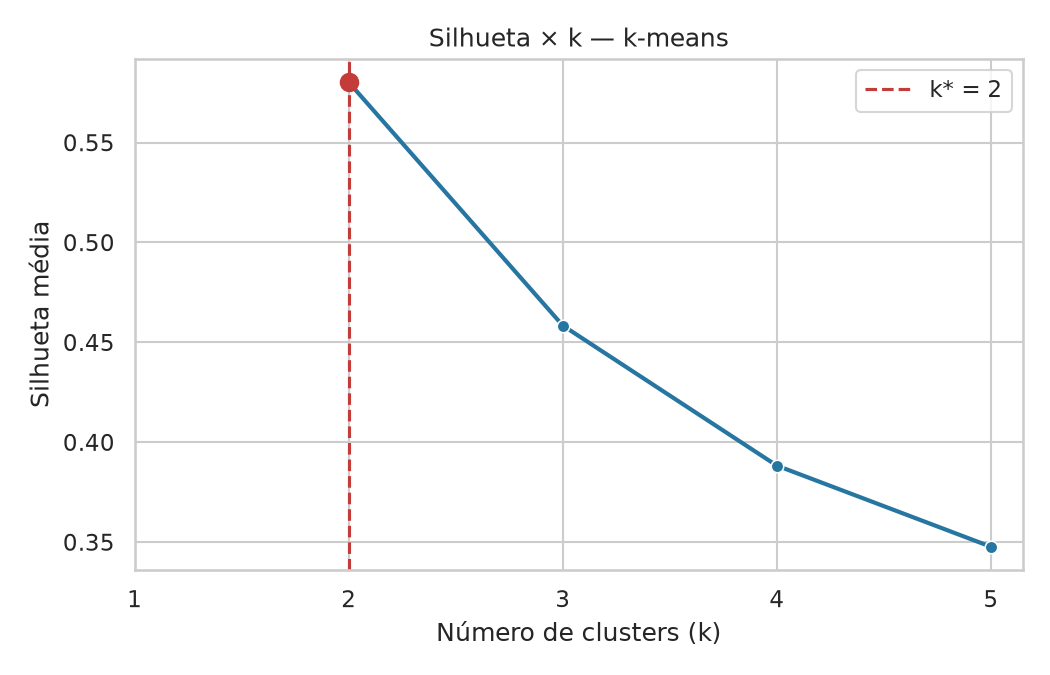

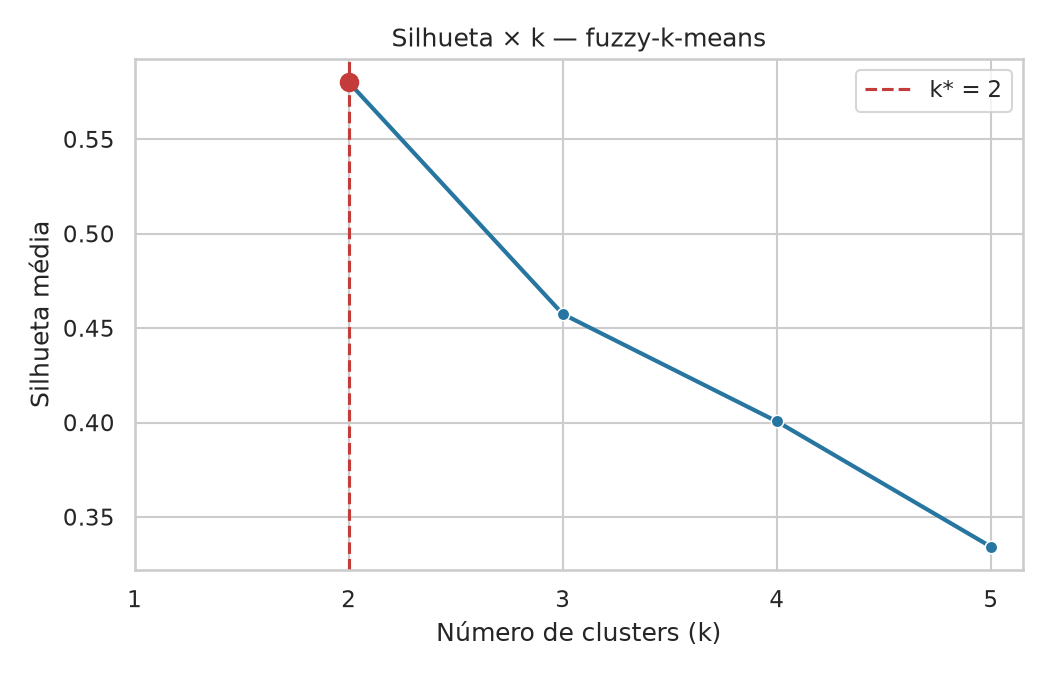

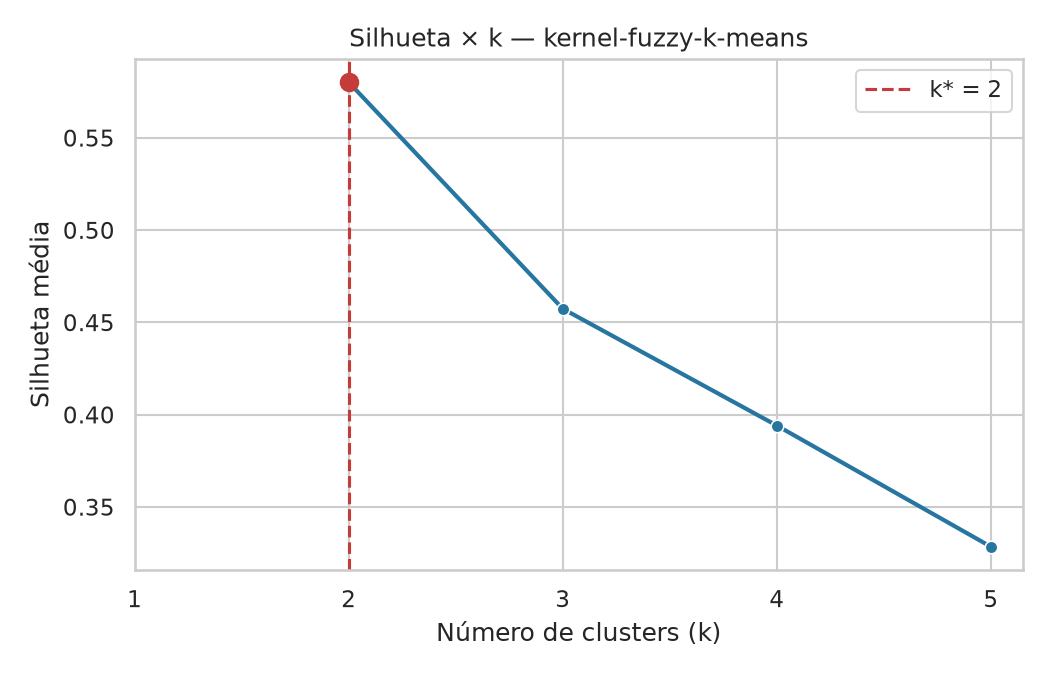

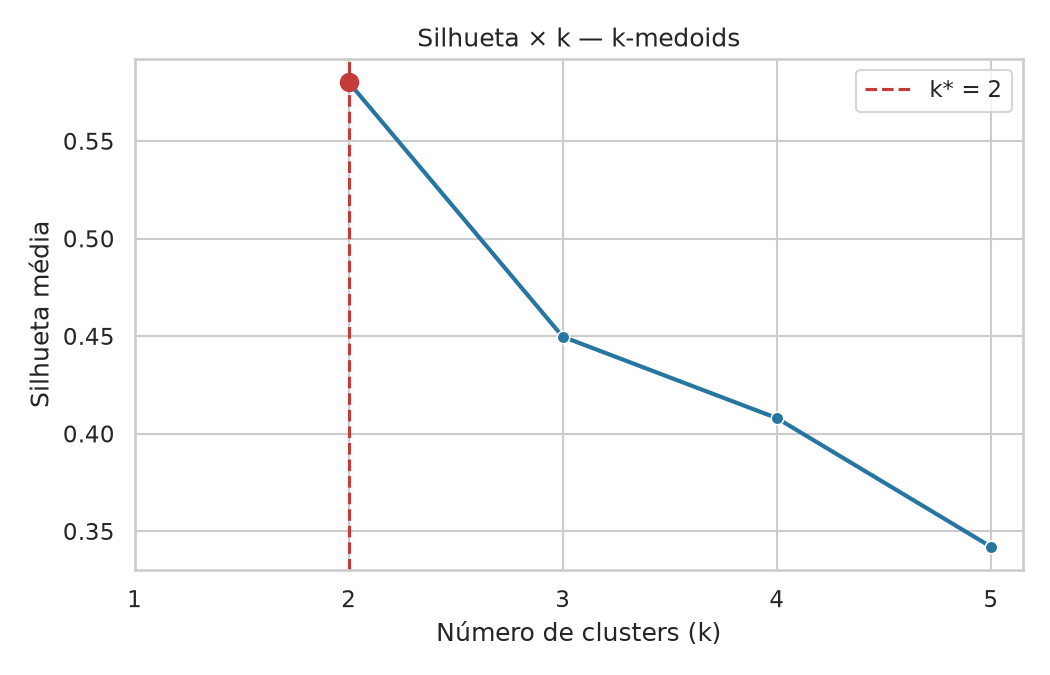

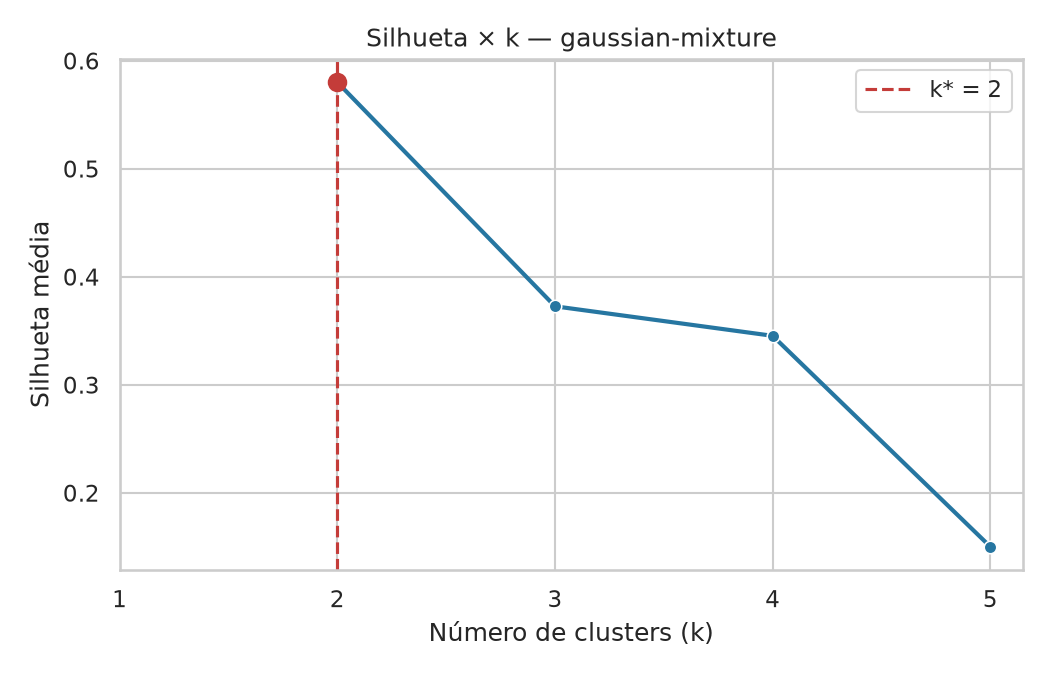

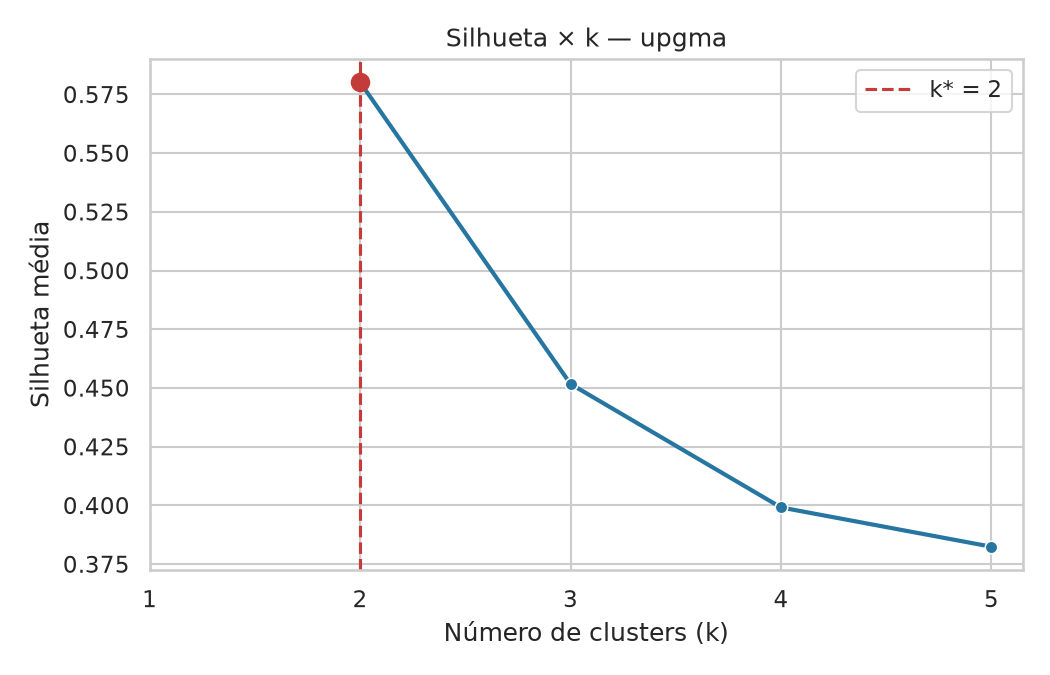

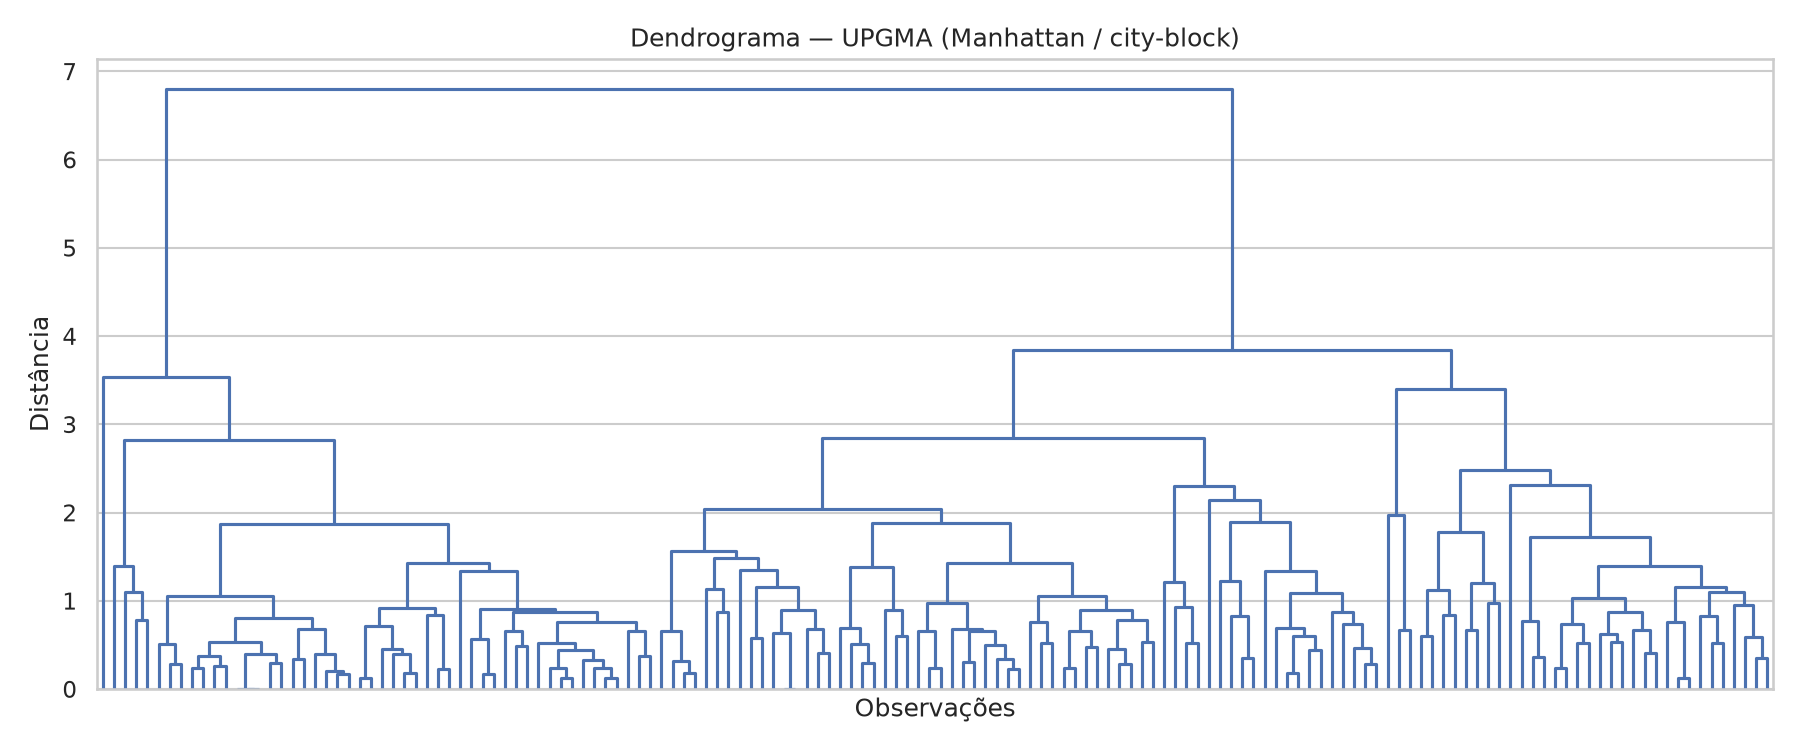

In [33]:
for nome in ("k_means", "fuzzy_k_means", "kernel_fuzzy_k_means", "k_medoids", "gaussian_mixture", "upgma"):
    mostrar_imagem(BASE / "figuras" / f"silhueta_{nome}.png")
mostrar_imagem(BASE / "figuras" / "dendrograma_upgma.png")

## 4. PCA, Kernel PCA, t-SNE e UMAP

As espécies só são usadas na identificação visual. Coordenadas, parâmetros, autovalores, componentes, loadings e divergência KL são persistidos nos resultados.

In [34]:
"""Experimentos não supervisionados da Questão 2; espécies apenas nas figuras."""

In [35]:
from pathlib import Path
import importlib.metadata
import hashlib
import sys
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA, KernelPCA
from sklearn.manifold import TSNE, trustworthiness
from umap import UMAP

### `executar_questao_2`

Implementação do projeto.

In [36]:
def executar_questao_2(padronizar=True, seed=42, gamma=0.25,
                       perplexidade=30.0, vizinhos=15, min_dist=0.1):
    raiz = BASE
    saida, figuras = raiz / 'resultados', raiz / 'figuras'
    saida.mkdir(exist_ok=True)
    figuras.mkdir(exist_ok=True)
    X, y, prep = carregar_iris(padronizar=padronizar)
    modelos = {
        'pca': PCA(n_components=4, svd_solver='full'),
        'kernel_pca': KernelPCA(n_components=2, kernel='rbf', gamma=gamma, eigen_solver='dense'),
        'tsne': TSNE(n_components=2, perplexity=perplexidade, learning_rate='auto',
                     init='pca', max_iter=1000, random_state=seed),
        'umap': UMAP(n_components=2, n_neighbors=vizinhos, min_dist=min_dist,
                     metric='euclidean', random_state=seed, n_jobs=1),
    }
    resultados = {}
    for nome, modelo in modelos.items():
        print(f'Executando {nome}...', flush=True)
        Z = modelo.fit_transform(X)
        tabela = pd.DataFrame(Z, columns=[f'componente_{i+1}' for i in range(Z.shape[1])])
        tabela.insert(0, 'observacao', np.arange(1, len(X)+1))
        tabela['especie'] = y
        tabela.to_csv(saida / f'coordenadas_{nome}.csv', index=False)
        resultado = {'parametros': modelo.get_params(), 'coordenadas': Z,
                     'trustworthiness_10': trustworthiness(X, Z[:, :2], n_neighbors=10)}
        if nome == 'pca':
            resultado.update(componentes=modelo.components_, autovalores=modelo.explained_variance_,
                             variancia_explicada=modelo.explained_variance_ratio_,
                             variancia_acumulada=np.cumsum(modelo.explained_variance_ratio_),
                             valores_singulares=modelo.singular_values_, media=modelo.mean_,
                             loadings=modelo.components_.T * np.sqrt(modelo.explained_variance_),
                             convencao_loadings='autovetores multiplicados pela raiz do autovalor')
            pd.DataFrame(modelo.components_.T, index=prep['atributos'], columns=['PC1','PC2','PC3','PC4']).to_csv(saida / 'pca_componentes.csv')
            pd.DataFrame(resultado['loadings'], index=prep['atributos'], columns=['PC1','PC2','PC3','PC4']).to_csv(saida / 'pca_loadings.csv')
        elif nome == 'kernel_pca':
            resultado.update(autovalores=modelo.eigenvalues_, autovetores=modelo.eigenvectors_)
        elif nome == 'tsne':
            resultado.update(divergencia_kl=modelo.kl_divergence_, iteracoes=modelo.n_iter_,
                             taxa_aprendizado_efetiva=modelo.learning_rate_)
        resultados[nome] = resultado
        sns.set_theme(style='whitegrid')
        fig, ax = plt.subplots(figsize=(8,5))
        sns.scatterplot(x=Z[:,0], y=Z[:,1], hue=y, style=y, s=48, ax=ax)
        ax.set(title=nome.upper().replace('_', ' ') + ' — Iris padronizada' if padronizar else nome.upper(),
               xlabel='Componente 1', ylabel='Componente 2')
        if nome == 'pca':
            ax.set_xlabel(f'PC1 ({modelo.explained_variance_ratio_[0]:.2%})')
            ax.set_ylabel(f'PC2 ({modelo.explained_variance_ratio_[1]:.2%})')
        ax.legend(title='Espécie', fontsize=8)
        fig.tight_layout()
        fig.savefig(figuras / f'{nome}.png', dpi=170)
        plt.close(fig)
    salvar_json(saida / 'execucoes_questao_2.json', resultados)
    salvar_json(saida / 'metadados_questao_2.json', {
        'preprocessamento': prep, 'seed': seed, 'python': sys.version,
        'fonte_requisitos': 'Projeto-AMG-NS-2026-2.pdf; Equipe 08',
        'sha256_dados': hashlib.sha256((raiz/'iris/iris.data').read_bytes()).hexdigest(),
        'versoes': {p: importlib.metadata.version(p) for p in
                    ['numpy','pandas','scikit-learn','scipy','umap-learn','numba','matplotlib']}})
    return resultados

Executando pca...
Executando kernel_pca...
Executando tsne...
Executando umap...


,trustworthiness_10
pca,0.978156
kernel_pca,0.932238
tsne,0.988813
umap,0.978349


,autovalor,variancia_explicada,variancia_acumulada
PC1,2.930354,0.727705,0.727705
PC2,0.927404,0.230305,0.958010
PC3,0.148342,0.036838,0.994848
PC4,0.020746,0.005152,1.000000


,PC1,PC2,PC3,PC4
sepal_length,0.522372,0.372318,0.721017,-0.261996
sepal_width,-0.263355,0.925556,-0.242033,0.124135
petal_length,0.581254,0.021095,-0.140892,0.801154
petal_width,0.565611,0.065416,-0.633801,-0.523546


,PC1,PC2,PC3,PC4
sepal_length,0.894210,0.358549,0.277701,-0.037736
sepal_width,-0.450818,0.891328,-0.093219,0.017880
petal_length,0.995007,0.020315,-0.054265,0.115394
petal_width,0.968229,0.062997,-0.244110,-0.075409


Autovalores Kernel PCA: [39.13208021 17.7923697 ]
KL final t-SNE: 0.16419735550880432


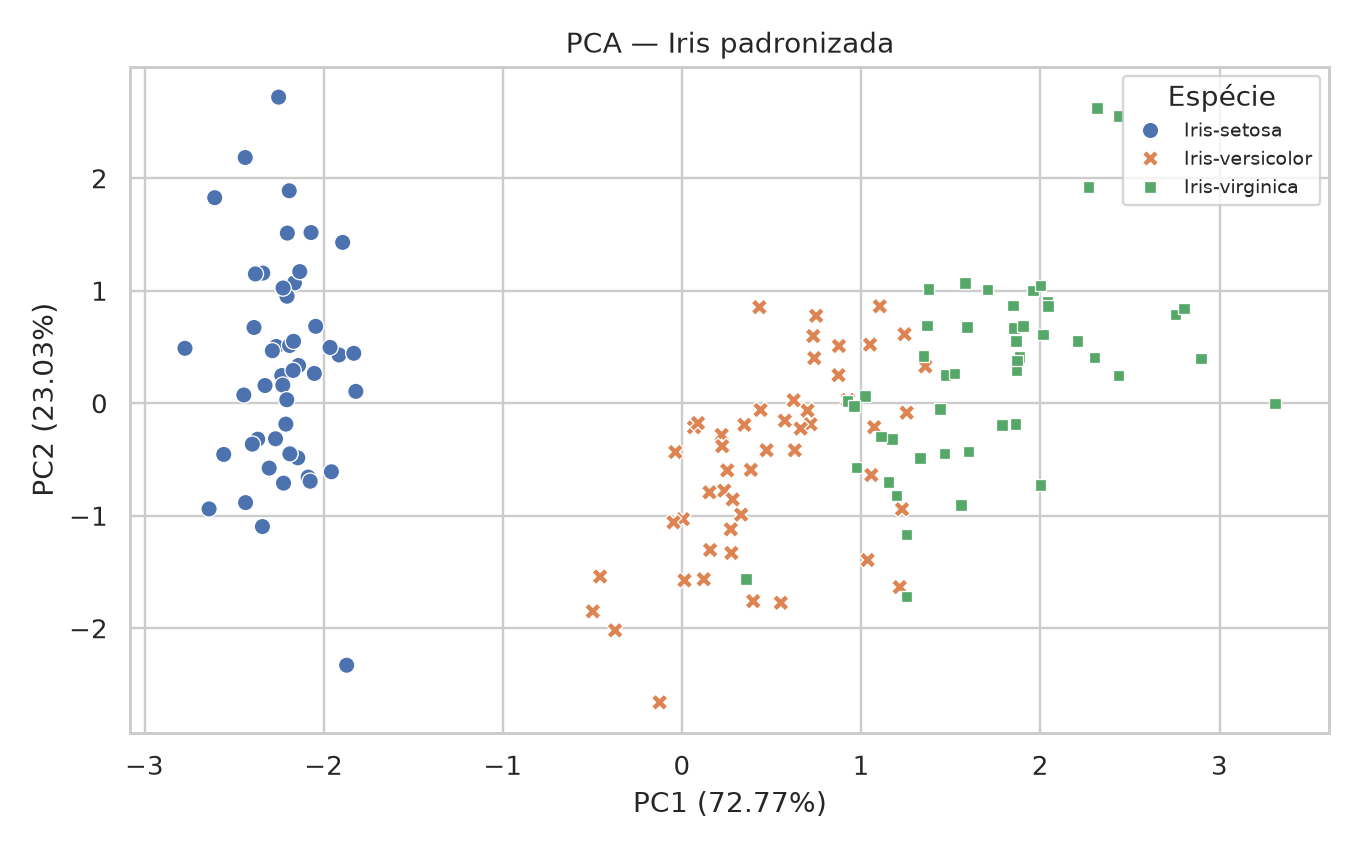

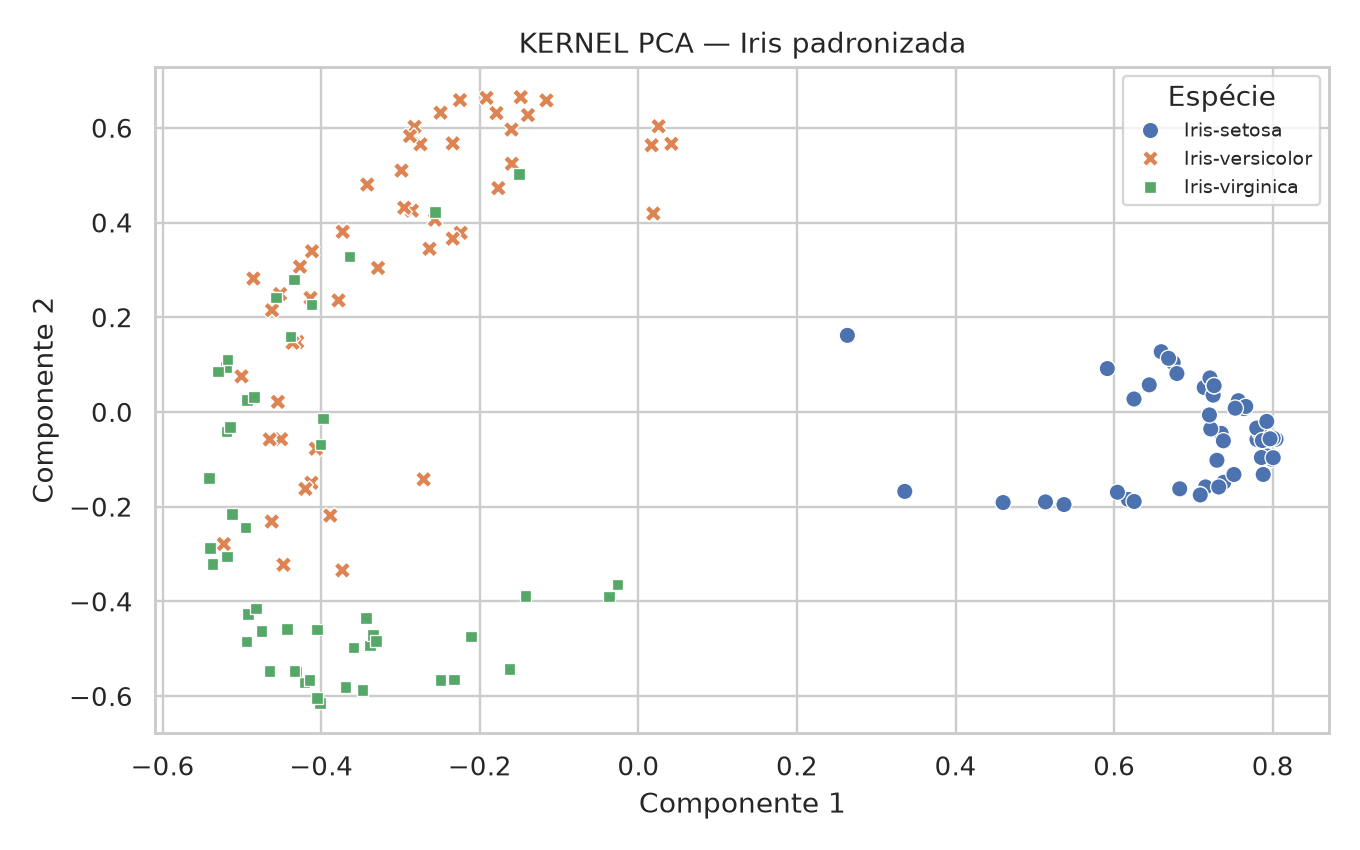

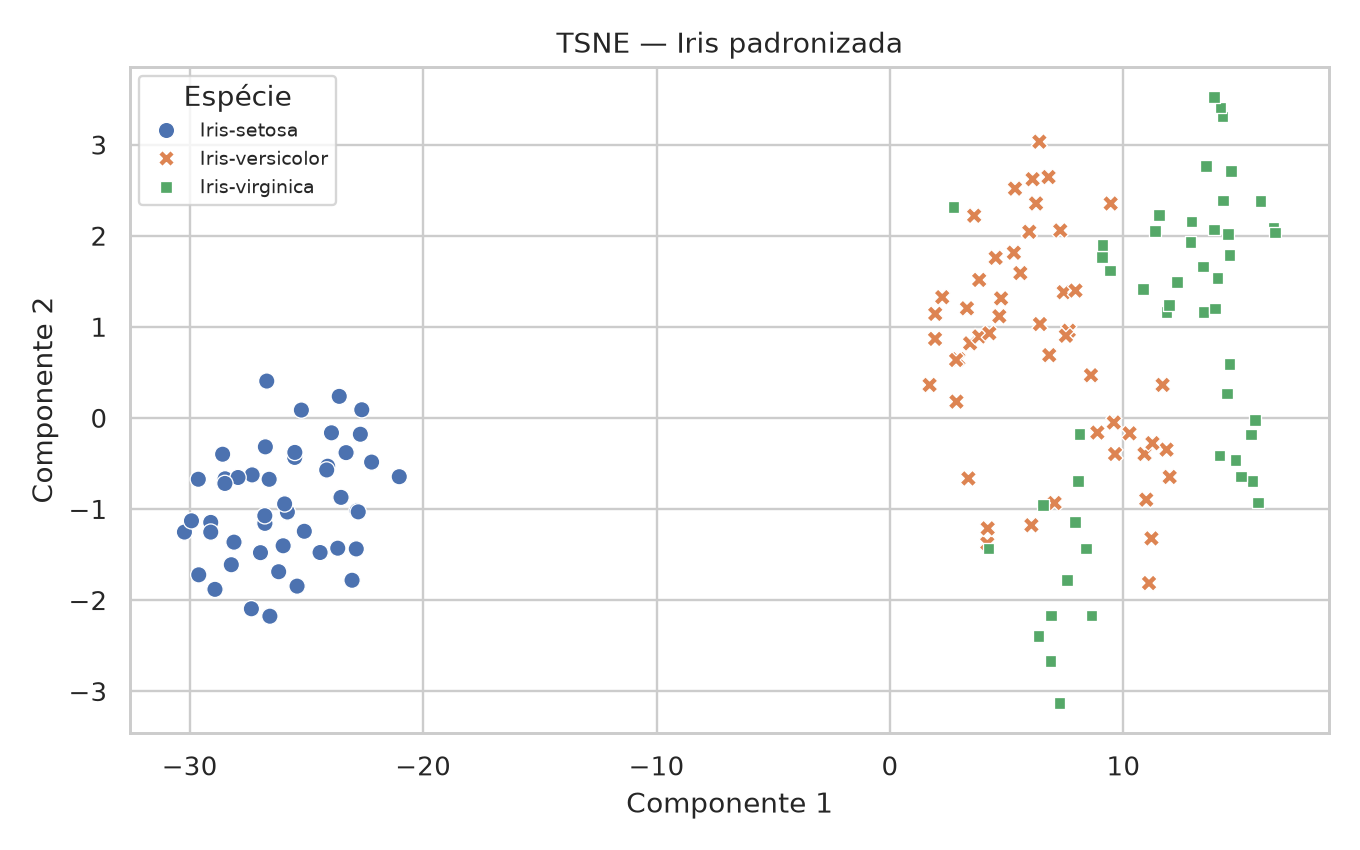

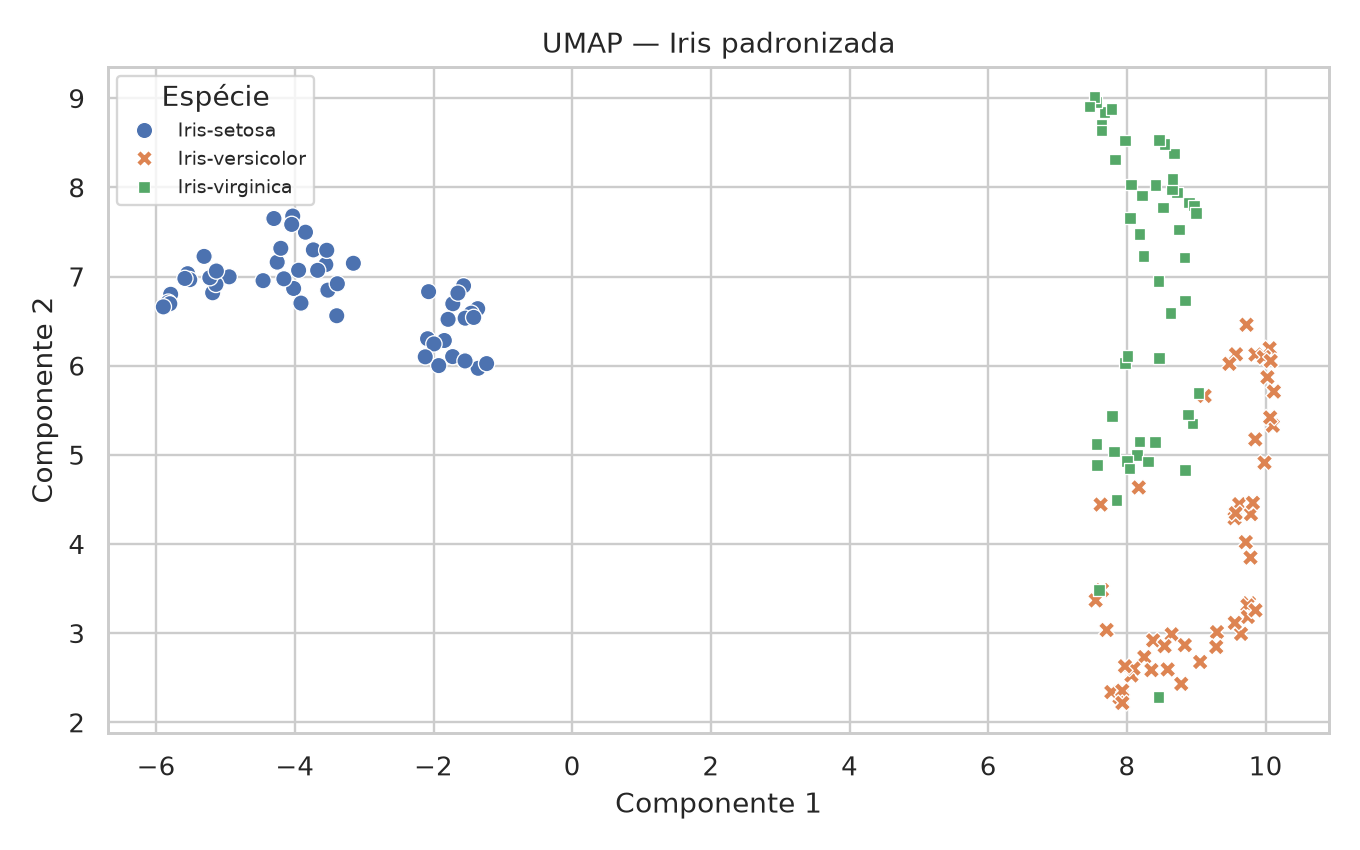

In [37]:
resultados_reducao = executar_questao_2(
    padronizar=True, seed=42, gamma=0.25,
    perplexidade=30.0, vizinhos=15, min_dist=0.1,
)
mostrar(pd.DataFrame({nome: {"trustworthiness_10": r["trustworthiness_10"]}
                     for nome, r in resultados_reducao.items()}).T)
pca_resultado = resultados_reducao["pca"]
mostrar(pd.DataFrame({"autovalor": pca_resultado["autovalores"],
                      "variancia_explicada": pca_resultado["variancia_explicada"],
                      "variancia_acumulada": pca_resultado["variancia_acumulada"]},
                     index=["PC1", "PC2", "PC3", "PC4"]))
mostrar(pd.read_csv(BASE / "resultados" / "pca_componentes.csv", index_col=0))
mostrar(pd.read_csv(BASE / "resultados" / "pca_loadings.csv", index_col=0))
print("Autovalores Kernel PCA:", resultados_reducao["kernel_pca"]["autovalores"])
print("KL final t-SNE:", resultados_reducao["tsne"]["divergencia_kl"])
for nome in ("pca", "kernel_pca", "tsne", "umap"):
    mostrar_imagem(BASE / "figuras" / f"{nome}.png")

## 5. Auditoria dos resultados

A auditoria abaixo corresponde à configuração padrão, com dados padronizados e sementes 42–51.

In [38]:
"""Audita os resultados persistidos contra o protocolo da Equipe 08."""

In [39]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score, silhouette_score

### `validar`

Implementação do projeto.

In [40]:
def validar():
    raiz = BASE / 'resultados'
    q1 = json.loads((raiz/'execucoes_questao_1.json').read_text())
    q2 = json.loads((raiz/'execucoes_questao_2.json').read_text())
    X, y, _ = carregar_iris()
    metricas = pd.read_csv(raiz/'metricas_por_k.csv')
    total = 2
    for nome, por_k in q1.items():
        if nome in ('upgma', 'dbscan'):
            continue
        assert set(por_k) == {'1','2','3','4','5'}
        for k, runs in por_k.items():
            assert len(runs) == 10
            assert [r['parametros']['seed'] for r in runs] == list(range(42,52))
            total += len(runs)
            melhor = (max if nome == 'gaussian-mixture' else min)(runs, key=lambda r:r['objetivo'])
            linha = metricas[(metricas.algoritmo == nome) & (metricas.k == int(k))].iloc[0]
            assert np.isclose(linha.objetivo, melhor['objetivo'])
            assert np.isclose(linha.ari, adjusted_rand_score(y, melhor['rotulos']))
            if k == '1':
                assert np.isnan(linha.silhueta)
            else:
                assert np.isclose(linha.silhueta, silhouette_score(X, melhor['rotulos']))
            for r in runs:
                assert len(r['rotulos']) == 150
                for chave in ('pertinencias', 'probabilidades'):
                    if r[chave] is not None:
                        u = np.array(r[chave])
                        assert u.shape == (150,int(k))
                        assert np.allclose(u.sum(axis=1), 1)
                        assert np.array_equal(u.argmax(axis=1), r['rotulos'])
    assert total == 252
    for nome, r in q2.items():
        z = np.array(r['coordenadas'])
        assert z.shape == (150,4 if nome == 'pca' else 2)
        assert np.isfinite(z).all()
        assert 0 <= r['trustworthiness_10'] <= 1
    assert np.isclose(sum(q2['pca']['variancia_explicada']), 1)
    assert q2['tsne']['divergencia_kl'] >= 0
    salvar_json(raiz/'validacao.json', {'status':'aprovado', 'ajustes_questao_1':total,
        'tecnicas_questao_2':len(q2), 'verificacoes':[
            'sementes e contagens', 'ótimos por função objetivo', 'silhuetas e ARI recalculados',
            'normalização e argmax das pertinências e probabilidades',
            'dimensões e finitude das projeções', 'variância PCA e KL t-SNE']})
    print('Validação aprovada: 252 ajustes e quatro técnicas de redução.')

In [41]:
validar()
mostrar(json.loads((BASE / "resultados" / "validacao.json").read_text()))

Validação aprovada: 252 ajustes e quatro técnicas de redução.


{'status': 'aprovado', 'ajustes_questao_1': 252, 'tecnicas_questao_2': 4, 'verificacoes': ['sementes e contagens', 'ótimos por função objetivo', 'silhuetas e ARI recalculados', 'normalização e argmax das pertinências e probabilidades', 'dimensões e finitude das projeções', 'variância PCA e KL t-SNE']}

## 6. Relatório detalhado e artigo IEEE

Os geradores completos estão incorporados nas células abaixo. A discussão textual corresponde aos parâmetros padrão. A autoria está identificada como Equipe 08.

### Relatório detalhado

In [42]:
def gerar_relatorio_notebook():
    """Gera o relatório Typst a partir dos resultados locais efetivamente executados."""
    from pathlib import Path
    import json
    import pandas as pd

    ROOT = BASE
    R = ROOT/'resultados'
    q2 = json.loads((R/'execucoes_questao_2.json').read_text())
    q1 = json.loads((R/'execucoes_questao_1.json').read_text())
    m = pd.read_csv(R/'metricas_por_k.csv')
    nomes = {'k-means':'K-Means','fuzzy-k-means':'Fuzzy K-Means', 'kernel-fuzzy-k-means':'Kernel Fuzzy K-Means', 'k-medoids':'K-Medoids', 'gaussian-mixture':'GMM/EM','upgma':'UPGMA','dbscan':'DBSCAN'}

    def fmt(x):
        if pd.isna(x): return '—'
        if isinstance(x,(float,int)): return f'{x:.4f}'.replace('.',',')
        return str(x).replace('_', r'\_')

    def tabela(headers, rows):
        cells = ',\n'.join('['+fmt(c)+']' for row in rows for c in row)
        return '#table(columns: '+str(len(headers))+', inset: 5pt, stroke: .35pt, table.header('+','.join('[*'+h+'*]' for h in headers)+'),\n'+cells+'\n)\n'

    def figura(nome, legenda, largura='90%'):
        return f'#figure(image("figuras/{nome}.png", width: {largura}), caption: [{legenda}])\n'

    s = '''#set document(title: "Agrupamento e redução de dimensionalidade na base Iris", author: "Equipe 08")
    #set page(paper: "a4", margin: 2cm, numbering: "1")
    #set text(font: "Libertinus Serif", size: 10.5pt, lang: "pt")
    #set par(justify: true, leading: .6em)
    #set heading(numbering: "1.1")
    #align(center)[
    #v(2cm)
    #text(size: 21pt, weight: "bold")[Agrupamento e redução de dimensionalidade na base Iris]
    #v(1cm)
    #text(size: 14pt)[Projeto de Aprendizado de Máquina Não Supervisionado]
    #v(2cm)
    *Equipe 08*
    #v(2cm)
    Centro de Informática — UFPE \\
    Novembro de 2026
    ]
    #pagebreak()
    #outline(title: [Sumário], depth: 2)
    #pagebreak()
    = Objetivo e aderência ao enunciado
    A única fonte dos requisitos deste trabalho é o documento *Projeto-AMG-NS-2026-2.pdf*, de Francisco de A. T. de Carvalho. Para a Equipe 08, foram executados K-Means, Fuzzy K-Means, Kernel Fuzzy K-Means, K-Medoids euclidiano, misturas gaussianas via EM, UPGMA com distância city-block e DBSCAN. A Questão 2 contempla PCA, Kernel PCA, t-SNE e UMAP, com saídas numéricas, gráficos e interpretação.

    O PDF determina dez execuções para cada valor de k de 1 a 5 nos métodos particionais e uma execução para UPGMA e DBSCAN. Foram realizados 250 ajustes particionais, uma hierarquia e um DBSCAN: 252 execuções principais. Os cinco cortes da hierarquia reutilizam o mesmo ajuste. A implementação de Kernel Fuzzy K-Means inicializa seus protótipos com FCM internamente; essas operações internas não são contadas como experimentos independentes. A busca exaustiva de K-Medoids com k igual a 1 é repetida nas dez chamadas, produzindo o mesmo ótimo.

    As escolhas de padronização, sementes, kernel, hiperparâmetros e convenções de avaliação abaixo são decisões metodológicas da equipe, não exigências adicionais atribuídas ao PDF. As análises complementares de ARI por k e preservação de vizinhanças não alteram o protocolo de seleção solicitado.

    = Dados e preparação
    Foi utilizado o arquivo local `iris/iris.data`, com 150 observações e quatro atributos em centímetros: comprimento e largura de sépala e comprimento e largura de pétala. Há 50 observações por espécie: Iris-setosa, Iris-versicolor e Iris-virginica. Linhas completamente vazias são ignoradas. A matriz numérica é separada dos rótulos antes dos ajustes; os rótulos servem apenas à avaliação externa e às cores e símbolos das figuras.

    Cada atributo foi transformado pela subtração da média e divisão pelo desvio-padrão populacional, usando StandardScaler. Isso confere escala unitária às variáveis. Essa opção altera a geometria em relação aos dados em centímetros e influencia as conclusões. Não foi feita divisão treino/teste, pois o objetivo é a análise descritiva não supervisionada da base fornecida, e não a estimação de desempenho preditivo em novos dados.
    '''
    meta=json.loads((R/'metadados_questao_1.json').read_text())['preprocessamento']
    s+=tabela(['Atributo','Média (cm)','Escala (cm)'],zip(meta['atributos'],meta['media_original'],meta['escala_original']))
    s+='''
    = Questão 1: protocolo e métodos
    == Reinicializações e seleção
    Para cada algoritmo particional e cada k, foram usadas as sementes 42 a 51, com uma inicialização por chamada. Primeiro selecionou-se a execução de melhor função objetivo dentro de cada k; somente então se calculou a silhueta da partição crisp escolhida. O melhor k foi definido pela maior silhueta válida. Em caso de empate na função objetivo, o código retém a primeira execução na ordem das sementes.

    K-Means minimiza a soma de quadrados das distâncias aos centroides. Utilizou-se inicialização aleatória, uma inicialização por chamada e os demais controles registrados no código e nas bibliotecas fixadas.

    Fuzzy K-Means minimiza a soma das distâncias euclidianas quadráticas ponderadas pelas pertinências elevadas ao expoente m. Foram usados m igual a 2, limite de 300 iterações e tolerância de 0,00001. O grupo crisp de cada ponto é o de maior pertinência.

    Kernel Fuzzy K-Means usa kernel RBF, K(x,v) = exp(−0,25‖x−v‖²), m igual a 2 e os mesmos limites do FCM. A distância quadrática no espaço induzido é 2(1−K(x,v)). Os protótipos permanecem no espaço de entrada e são atualizados com ponderação pelo kernel; essa é a variante implementada pela biblioteca fcmeans instalada. A função objetivo registrada corresponde a essa variante, e não a uma formulação com protótipos irrestritos no espaço de características.

    K-Medoids utiliza PAM e minimiza a soma das distâncias euclidianas aos medoides, que são observações reais. Para k maior que 1, a inicialização é aleatória e o limite é 300 iterações; para k igual a 1, seleciona-se diretamente a observação de menor soma de distâncias.

    GMM/EM ajusta componentes com covariâncias completas. Foram usados tolerância de 0,00001, regularização de covariância de 0,000001, uma inicialização e inicialização `random_from_data`. A seleção maximiza a log-verossimilhança total calculada no modelo final, somando as log-densidades dos 150 pontos. O grupo crisp é o componente de maior probabilidade posterior. As funções objetivo dos diferentes algoritmos têm escalas e significados distintos; seus valores não são comparados entre métodos.

    UPGMA constrói uma única árvore usando distância Manhattan (city-block) e ligação média não ponderada. A distância entre grupos é a média das distâncias entre todos os pares de observações dos grupos. Os cortes com 1 a 5 grupos são extraídos da árvore.

    DBSCAN utiliza distância euclidiana, eps igual a 0,8 e `min_samples` igual a 5, incluindo o próprio ponto na contagem da vizinhança. Esses valores foram mantidos da configuração experimental existente e não foram otimizados com os rótulos das espécies. Representam uma configuração exploratória única; não se afirma que sejam ótimos.

    == Avaliação
    Para cada ponto i, a silhueta é
    $ s(i) = (b(i)-a(i))/max(a(i), b(i)) $,
    em que a(i) é a distância média intragrupo e b(i) é a menor distância média a outro grupo. A avaliação utiliza distância euclidiana em todos os métodos, inclusive UPGMA, cuja construção usa Manhattan. Essa convenção facilita a comparação geométrica, mas não coincide com o critério de construção da árvore. Grupos unitários recebem a convenção de silhueta zero da biblioteca. Para uma única partição global, a silhueta é indefinida e não participa da seleção.

    O ARI compara pares de observações nas partições predita e verdadeira, descontando a concordância esperada ao acaso. Vale 1 para partições idênticas, sem depender dos números atribuídos aos grupos; valores próximos de zero indicam concordância próxima à referência de acaso. O ARI não foi utilizado para escolher execuções, hiperparâmetros ou k.

    No DBSCAN, a silhueta é calculada nos pontos não classificados como ruído, desde que haja ao menos dois grupos válidos. O ARI inclui todos os pontos e mantém −1 como rótulo do ruído. Assim, a silhueta do DBSCAN avalia um subconjunto diferente dos demais métodos.

    == Resultados consolidados
    '''
    a=pd.read_csv(R/'resumo_agrupamentos.csv')
    s+=tabela(['Método','k escolhido','Silhueta','ARI','Ruído'],[[nomes[r['Algoritmo']],str(r['k*']),r['Silhueta'],r['ARI'],str(r['Ruído'])] for _,r in a.iterrows()])
    s+='''
    Todos os seis métodos com seleção de k escolheram dois grupos e produziram a mesma partição, salvo permutação dos identificadores: um grupo contém as 50 setosas e o outro reúne as 50 versicolors e as 50 virginicas. Isso explica a igualdade das métricas, sem implicar igualdade dos centros, pertinências ou funções objetivo.

    O DBSCAN reteve 49 setosas em um grupo e 50 versicolors mais 47 virginicas no outro. O ruído contém uma setosa e três virginicas: quatro pontos, ou 2,67% da base. Sua silhueta de 0,5963 supera numericamente 0,5802, mas exclui esses quatro pontos; portanto, não demonstra superioridade global. O ARI de 0,5518 é inferior ao dos demais resultados selecionados.

    == Silhuetas e comparação por k
    A tabela apresenta as silhuetas após a seleção pela função objetivo. Para todos os métodos, k igual a 1 é indefinido.
    '''
    s+=tabela(['Método','k = 2','k = 3','k = 4','k = 5'],[[nomes[n]]+[m[(m.algoritmo==n)&(m.k==k)].iloc[0].silhueta for k in range(2,6)] for n in nomes if n!='dbscan'])
    for n in nomes:
        if n=='dbscan': continue
        s+=figura('silhueta_'+n.replace('-','_'),'Silhueta após seleção da execução por função objetivo: '+nomes[n]+'.', '72%')
    s+='''
    A silhueta cai ao subdividir o bloco formado por versicolor e virginica. Isso favorece k igual a 2, apesar das três classes biológicas. O efeito é especialmente claro no GMM: a partição de três componentes tem menor silhueta, embora corresponda muito melhor às espécies. A tabela seguinte usa k igual a 3 apenas para interpretação posterior; ela não substitui a seleção exigida no enunciado.
    '''
    s+=tabela(['Método','Silhueta em k = 3','ARI em k = 3'],[[nomes[r.algoritmo],r.silhueta,r.ari] for _,r in m[m.k==3].iterrows()])
    s+='''
    O GMM obtém ARI de 0,9039 em k igual a 3, contra 0,5681 na solução escolhida pela silhueta. A modelagem por covariâncias completas permite grupos com formas distintas, enquanto a silhueta euclidiana favorece separação compacta. UPGMA alcança ARI de 0,7184 e K-Medoids 0,6765 em três grupos. Esses valores mostram que a avaliação interna e a recuperação das espécies respondem a perguntas diferentes. Não houve escolha retroativa pelo melhor ARI.

    == Hierarquia e dendrograma
    '''+figura('dendrograma_upgma','Uma única árvore UPGMA, construída com distância Manhattan e ligação média.')+'''
    O dendrograma registra a sequência de fusões; a altura corresponde à distância de ligação média na escala padronizada. O corte em dois grupos separa setosa das demais espécies. Cortes mais finos aumentam a correspondência com as espécies em alguns casos, mas reduzem a silhueta euclidiana. A árvore representa relações de proximidade, e não uma filogenia ou evidência causal.

    = Questão 2: redução de dimensionalidade
    As quatro técnicas receberam a mesma matriz padronizada de quatro atributos, sem rótulos de espécie durante o ajuste. As cores foram adicionadas posteriormente. PCA foi ajustada com quatro componentes para apresentar o espectro completo; seu gráfico usa apenas as duas primeiras. Os outros métodos foram ajustados diretamente para duas dimensões. As 150 coordenadas de cada método foram exportadas em CSV, com identificador de observação e espécie.

    == PCA
    A PCA utiliza decomposição SVD completa. As componentes são combinações lineares ortogonais dos atributos padronizados. A tabela mostra os autovalores da covariância amostral, as proporções explicadas e a soma acumulada.
    '''
    p=q2['pca']
    s+=tabela(['Componente','Autovalor','Variância (%)','Acumulada (%)'],[[f'PC{i+1}',p['autovalores'][i],100*p['variancia_explicada'][i],100*p['variancia_acumulada'][i]] for i in range(4)])
    s+='As duas primeiras componentes retêm 95,80% da variância da matriz padronizada. As duas omitidas representam 4,20%; portanto, o gráfico bidimensional preserva a maior parte da variabilidade linear, mas não toda a informação.\n\nCoeficientes das componentes (autovetores):\n'
    s+=tabela(['Atributo','PC1','PC2','PC3','PC4'],[[attr]+[p['componentes'][j][i] for j in range(4)] for i,attr in enumerate(meta['atributos'])])
    s+='''
    PC1 atribui pesos positivos ao comprimento de sépala e às duas medidas de pétala, com peso negativo para largura de sépala. PC2 é dominada pela largura de sépala (coeficiente 0,9256). O sinal de um autovetor pode ser invertido sem alterar a solução; a interpretação depende dos pesos relativos.

    Adotou-se como convenção de loadings o autovetor multiplicado pela raiz do autovalor. Esses valores não são exatamente os coeficientes acima nem, sem ajuste de escala amostral, as correlações com os atributos, pois StandardScaler usa variância populacional e a PCA reporta covariância amostral.
    '''
    s+=tabela(['Atributo','Loading 1','Loading 2','Loading 3','Loading 4'],[[attr]+p['loadings'][i] for i,attr in enumerate(meta['atributos'])])
    s+=figura('pca','Projeção linear nas duas primeiras componentes principais.')
    s+='''
    A projeção destaca a separação de setosa e a maior proximidade entre versicolor e virginica. A interpretação dos eixos pelos atributos é uma vantagem da PCA neste conjunto pequeno. A elevada variância retida não garante separação perfeita entre as espécies, pois variância e discriminação de classes não são o mesmo objetivo.

    == Kernel PCA
    Foi usado kernel RBF com gamma igual a 0,25, matriz de kernel centralizada, duas componentes e decomposição espectral densa. Essa escolha corresponde a uma escala característica de distância igual a 2 nas unidades padronizadas, pois o kernel vale exp(−1) nessa distância. O valor foi fixado, sem busca orientada pelas espécies.
    '''
    s+=tabela(['Componente','Autovalor do kernel centralizado'],[[str(i+1),v] for i,v in enumerate(q2['kernel_pca']['autovalores'])])
    s+=figura('kernel_pca','Duas primeiras componentes da Kernel PCA com kernel RBF.')
    s+='''
    Os autovalores acima pertencem à matriz de kernel centralizada, não à covariância dos quatro atributos originais. Como foram retidas apenas duas componentes, não se divide sua soma para declarar uma porcentagem de variância original explicada. A transformação curva a organização dos pontos e evidencia relações não lineares, mas torna a interpretação por pesos dos atributos menos direta. A escolha de gamma altera a noção de proximidade e não foi submetida a análise de sensibilidade.

    == t-SNE
    Foram usados perplexidade 30, inicialização por PCA, distância euclidiana, semente 42, exagero inicial 12, método Barnes-Hut com ângulo 0,5 e limite de 1.000 iterações. A taxa de aprendizado automática efetiva foi 50. A perplexidade controla a escala de vizinhança, sem representar um número de grupos.
    '''
    s+=tabela(['Saída','Valor'],[['Divergência KL final',q2['tsne']['divergencia_kl']],['n_iter_ reportado',str(q2['tsne']['iteracoes'])],['Taxa efetiva',q2['tsne']['taxa_aprendizado_efetiva']]])
    s+=figura('tsne','Projeção t-SNE com perplexidade 30 e semente 42.')
    s+='''
    Setosa aparece isolada à esquerda, enquanto versicolor e virginica ocupam regiões próximas e parcialmente misturadas à direita. A divergência KL final quantifica o objetivo de preservação de afinidades desse ajuste, não uma taxa de erro de classificação. O atributo `n_iter_` reporta 999; não se toma o esgotamento do orçamento como prova de ótimo global. Distâncias entre ilhas, tamanhos e áreas não devem ser interpretados como distâncias e densidades fiéis do espaço original. Os eixos não têm o significado de componentes lineares nem proporção de variância explicada.

    == UMAP
    Foram usados 15 vizinhos, `min_dist` igual a 0,1, spread igual a 1, duas dimensões, distância euclidiana, inicialização espectral e semente 42. A execução foi limitada a uma thread para reprodutibilidade. O número de épocas foi deixado no modo automático da biblioteca, registrado como `n_epochs` nulo nos parâmetros; não se declara aqui um contador de épocas observado.
    '''
    s+=figura('umap','Projeção UMAP com 15 vizinhos e `min_dist` igual a 0,1.')
    s+='''
    Setosa forma uma região separada à esquerda. Versicolor e virginica aparecem à direita, com tendência de organização vertical e pontos misturados na transição. Os 15 vizinhos definem a escala da estrutura local; `min_dist` controla a compactação permitida na projeção. Distâncias entre regiões desconectadas e a orientação dos eixos não têm interpretação física direta. A presença de subestruturas visuais não demonstra novas classes biológicas.

    == Comparação complementar das projeções
    Como diagnóstico adicional, calculou-se trustworthiness com dez vizinhos e distância euclidiana entre a matriz padronizada e cada representação 2D. Essa medida penaliza vizinhos artificiais introduzidos pela projeção; valores mais próximos de 1 são melhores nesse critério. Ela não utiliza espécies e não mede toda a estrutura global, nem equivale a acurácia.
    '''
    s+=tabela(['Projeção','Trustworthiness (10 vizinhos)'],[[n.upper().replace('_',' '),r['trustworthiness_10']] for n,r in q2.items()])
    s+='''
    Nesta execução, t-SNE apresentou o maior valor local (0,9888), seguido de UMAP (0,9783) e PCA (0,9782), muito próximos entre si. Kernel PCA obteve 0,9322. Essa ordenação é específica dos hiperparâmetros, da semente e da vizinhança escolhida; não constitui superioridade universal. PCA oferece interpretação direta e alta retenção de variância, enquanto t-SNE e UMAP enfatizam relações locais. Não foram executados agrupamentos sobre as projeções: as métricas da Questão 1 pertencem ao espaço original padronizado.

    = Limitações e conclusão
    Os resultados se referem ao arquivo local Iris, a uma padronização e a um conjunto fixo de hiperparâmetros. Dez reinicializações reduzem a dependência da inicialização dos agrupamentos, mas não asseguram ótimo global. Houve uma execução de cada projeção; não foram estimados intervalos de confiança ou estabilidade entre sementes. A sensibilidade de gamma, perplexidade, vizinhos e eps permanece fora desta análise.

    A principal conclusão dos agrupamentos é a distinção entre estrutura geométrica e classes conhecidas. Todos os métodos com escolha de k favoreceram dois grupos, separando setosa das demais espécies. Entretanto, GMM com três componentes teve concordância muito maior com os rótulos. O resultado não justifica substituir a seleção pela silhueta: ele esclarece o alcance da métrica exigida.

    As quatro projeções permitem visualizar a separação de setosa e a proximidade entre as outras espécies. PCA concentra 95,80% da variância nas duas primeiras componentes; t-SNE tem a maior preservação local pelo diagnóstico adotado. As figuras complementam os índices, sem provar que a estrutura visual corresponda a classes discretas perfeitamente recuperáveis.

    = Reprodutibilidade e artefatos
    Os experimentos são executados por `main.py`; os agrupamentos estão em `projeto.py` e as projeções em `reducao.py`. O arquivo `requirements.txt` fixa as versões instaladas. A exploração anterior de K-Means foi preservada em `exploracao_kmeans.py`.

    Os JSONs de execuções armazenam parâmetros, sementes, funções objetivo, rótulos, centros e pertinências ou probabilidades, quando aplicáveis. O arquivo `metricas_por_k.csv` identifica as sementes vencedoras e as métricas por k. Os metadados registram a padronização e versões; o arquivo da Questão 2 também registra o SHA-256 dos dados. Coordenadas, componentes e loadings são fornecidos em CSV, e as onze figuras ficam no diretório `figuras`.

    O comando `python validar_resultados.py` audita a contagem de 252 ajustes, as sementes, a seleção por objetivo, as métricas recalculadas, a normalização das pertinências e probabilidades, o argmax dos rótulos e a finitude das quatro projeções. O resultado da auditoria consta em `resultados/validacao.json`. Isso verifica o protocolo e a consistência numérica dos artefatos, sem constituir prova de otimalidade dos algoritmos.

    Para reproduzir, no ambiente com as dependências instaladas:
    ```sh
    python main.py
    python validar_resultados.py
    python gerar_relatorio.py
    typst compile relatorio.typ relatorio.pdf
    ```
    O relatório é gerado com tabelas dos arquivos de resultados. Sua discussão textual corresponde à configuração padrão desta entrega; mudanças de parâmetros exigem rever a interpretação, mesmo que as tabelas sejam atualizadas automaticamente.

    == Versões utilizadas
    '''
    vers=json.loads((R/'metadados_questao_1.json').read_text())['versoes']
    vers.update(json.loads((R/'metadados_questao_2.json').read_text())['versoes'])
    s+=tabela(['Pacote','Versão'],[[k,v] for k,v in vers.items() if k!='python'])
    s+='\n= Fonte dos requisitos\nFrancisco de A. T. de Carvalho. *Projeto AM-NS 2026-2*. Documento fornecido com a atividade, `Projeto-AMG-NS-2026-2.pdf`: Questão 1, páginas 2–3; Questão 2, página 4; atribuição da Equipe 08, página 6; orientações de entrega, página 7. O documento informa entrega e apresentação da Equipe 08 em 26/11/2026 e duração de 30 minutos, incluindo discussão.\n'
    (ROOT/'relatorio.typ').write_text(s)
    print('relatorio.typ atualizado com resultados executados.')

### Artigo IEEE e figuras vetoriais

In [43]:
def gerar_artigo_notebook():
    """Adapta o relatório validado ao estilo de artigo IEEE em duas colunas."""
    from pathlib import Path
    import re
    import json
    import pandas as pd
    import numpy as np
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    from scipy.cluster.hierarchy import dendrogram

    ROOT = BASE
    out = ROOT/'figuras'/'ieee'
    out.mkdir(exist_ok=True)
    plt.rcParams.update({'font.family':'serif', 'font.size':8, 'axes.labelsize':8,
                         'xtick.labelsize':7, 'ytick.labelsize':7, 'legend.fontsize':6.5})
    m = pd.read_csv(ROOT/'resultados/metricas_por_k.csv')
    for nome, linhas in m.groupby('algoritmo', sort=False):
        fig, ax=plt.subplots(figsize=(3.45,2.15))
        ax.plot(linhas.k,linhas.silhueta,'o-',lw=1,ms=3)
        best=linhas.loc[linhas.silhueta.idxmax()]
        ax.axvline(best.k,ls='--',color='#b32c34',lw=1,label=f'k* = {int(best.k)}')
        ax.set(xlabel='Número de grupos (k)',ylabel='Silhueta média',xticks=range(1,6))
        ax.text(1,0.04,'indefinida',rotation=90,transform=ax.get_xaxis_transform(),fontsize=7)
        ax.grid(alpha=.2); ax.legend(); fig.tight_layout(pad=.5)
        fig.savefig(out/f"silhueta_{nome.replace('-','_')}.pdf"); plt.close(fig)
    q1=json.loads((ROOT/'resultados/execucoes_questao_1.json').read_text())
    fig,ax=plt.subplots(figsize=(3.45,2.15))
    dendrogram(np.array(q1['upgma']['2']['hierarquia']),no_labels=True,color_threshold=0,ax=ax)
    ax.set(xlabel='Observações',ylabel='Distância Manhattan')
    fig.tight_layout(pad=.5);fig.savefig(out/'dendrograma_upgma.pdf');plt.close(fig)
    for nome in ['pca','kernel_pca','tsne','umap']:
        df=pd.read_csv(ROOT/f'resultados/coordenadas_{nome}.csv')
        fig,ax=plt.subplots(figsize=(3.45,2.35))
        for especie,cor,marker in zip(df.especie.unique(),['#2676a1','#c55b26','#438745'],['o','x','s']):
            d=df[df.especie==especie]
            ax.scatter(d.componente_1,d.componente_2,s=9,c=cor,marker=marker,label=especie.replace('Iris-',''),linewidths=.5)
        ax.set(xlabel='Componente 1',ylabel='Componente 2')
        if nome=='pca': ax.set(xlabel='PC1 (72,77%)',ylabel='PC2 (23,03%)')
        ax.legend(loc='best',framealpha=.85); ax.grid(alpha=.15)
        fig.tight_layout(pad=.5);fig.savefig(out/f'{nome}.pdf');plt.close(fig)

    s=(ROOT/'relatorio.typ').read_text()
    s=s[s.index('= Objetivo e aderência ao enunciado'):]
    s=s.replace('= Objetivo e aderência ao enunciado','= Introdução')
    start=s.index('A única fonte dos requisitos')
    end=s.index('= Dados e preparação')
    s=s[:start]+'''A análise não supervisionada pode revelar estruturas geométricas que não coincidem com classes conhecidas. Na base Iris, essa distinção permite comparar a seleção interna de agrupamentos com sua concordância externa com espécies botânicas. Este artigo avalia sete algoritmos de agrupamento e quatro técnicas de redução de dimensionalidade, seguindo o protocolo atribuído à Equipe 08 no enunciado do projeto [1].

    O objetivo é investigar quais partições são favorecidas pela silhueta, como elas se relacionam com as três espécies e quais estruturas são evidenciadas nas projeções bidimensionais. Foram realizados 252 ajustes principais: 250 ajustes particionais, uma hierarquia UPGMA e um DBSCAN. As projeções incluem PCA, Kernel PCA, t-SNE e UMAP. Os rótulos das espécies são utilizados apenas após os ajustes, para interpretação e avaliação externa.

    As contribuições deste estudo são a comparação sob um protocolo comum, o registro completo das execuções e a interpretação conjunta de silhueta, índice de Rand ajustado e projeções. Padronização, sementes e hiperparâmetros são escolhas metodológicas; os requisitos experimentais decorrem exclusivamente de [1].

    '''+s[end:]
    s=s.replace('= Dados e preparação','= Base de dados e preparação').replace('= Questão 1: protocolo e métodos','= Metodologia de agrupamento')
    s=s.replace('== Resultados consolidados','= Resultados de agrupamento\n== Comparação das partições selecionadas')
    s=s.replace('= Questão 2: redução de dimensionalidade','= Redução de dimensionalidade')
    s=s.replace('= Limitações e conclusão','= Discussão e limitações')
    s=s.replace('A principal conclusão dos agrupamentos','= Conclusão\nA principal conclusão dos agrupamentos')
    start=s.index('= Reprodutibilidade e artefatos')
    s=s[:start]+'''= Reprodutibilidade
    O código em Python separa agrupamentos (`projeto.py`), projeções (`reducao.py`) e execução (`main.py`). As versões utilizadas incluem NumPy 2.5.4, SciPy 1.18.1, scikit-learn 1.9.1, fuzzy-c-means 2.3.1, kmedoids 0.5.5 e umap-learn 0.5.12. As dependências completas são fixadas em `requirements.txt`.

    Os artefatos incluem rótulos por execução, objetivos, parâmetros, sementes, pertinências e probabilidades posteriores. As métricas por k, contingências, coordenadas das projeções, componentes e loadings foram exportados em CSV ou JSON. A auditoria verificou as 252 execuções principais, a seleção por objetivo, silhuetas e ARI recalculados, normalização e conversão crisp, além da finitude das quatro projeções. O hash dos dados e as versões foram registrados para rastreabilidade. A auditoria verifica consistência dos resultados, sem garantir otimalidade global.

    #heading(numbering: none)[Referências]
    #block[
    #set par(first-line-indent: 0pt, hanging-indent: 1.2em)
    [1] F. de A. T. de Carvalho, “Projeto AM-NS 2026-2,” Centro de Informática, Universidade Federal de Pernambuco, Recife, Brasil, enunciado de projeto, 2026, pp. 2–7. Arquivo fornecido: `Projeto-AMG-NS-2026-2.pdf`.
    ]
    '''
    s=s.replace('width: 72%','width: 100%').replace('width: 90%','width: 100%')
    s=re.sub(r'image\("figuras/([^".]+)\.png"',r'image("figuras/ieee/\1.pdf"',s)
    # Legendas e numeração de tabelas no estilo IEEE.
    pattern=r'#table\(.*?\n\)'
    captions=['Estatísticas dos atributos antes da padronização','Resultados das partições selecionadas',
              'Silhueta das melhores execuções por k','Avaliação complementar com três grupos',
              'Espectro e variância explicada da PCA','Coeficientes das componentes principais',
              'Loadings da PCA','Autovalores da Kernel PCA','Saídas do t-SNE','Preservação local das projeções']
    idx=iter(captions)
    def wrap(match):
        tab=match.group().replace('inset: 5pt, stroke: .35pt','inset: (x: 2pt, y: 3pt), stroke: .3pt')
        tab=tab.replace('[Kernel Fuzzy K-Means]','[Kernel FCM]').replace('[Fuzzy K-Means]','[FCM]')
        tab=tab.replace('[automático]','[auto.]')
        for a,b in [('sepal\\_length','Comp. sépala'),('sepal\\_width','Larg. sépala'),('petal\\_length','Comp. pétala'),('petal\\_width','Larg. pétala')]: tab=tab.replace(a,b)
        return '#figure(kind: table, supplement: [TABELA], numbering: "I", caption: ['+next(idx)+'], [\n#set text(size: 8pt)\n'+tab+'\n])'
    s=re.sub(pattern,wrap,s,flags=re.S)
    header='''// Artigo acadêmico em estilo IEEE conference (A4), implementado em Typst.
    // Compilar: typst compile artigo_ieee.typ artigo_ieee.pdf
    #set document(title: "Agrupamento e redução de dimensionalidade na base Iris: uma avaliação comparativa", author: "Equipe 08")
    #set page(paper: "a4", margin: (top: 19mm, bottom: 43mm, x: 13mm), numbering: none)
    #set text(font: "Nimbus Roman", size: 10pt, lang: "pt")
    #set par(justify: true, leading: .45em, spacing: .55em, first-line-indent: 1em)
    #set heading(numbering: "I.A.")
    #set figure(gap: 5pt)
    #show figure.caption: set text(size: 8pt)
    #show figure.caption.where(kind: image): set figure.caption(separator: [. ])
    #show figure.caption.where(kind: table): set figure.caption(separator: linebreak())
    #show figure.where(kind: table): set figure.caption(position: top)
    #show heading.where(level: 1): it => block(width: 100%, above: 1em, below: .6em)[
    #set par(justify: false, first-line-indent: 0pt)
    #align(center)[#text(weight: "regular", size: 10pt)[#if it.numbering != none {counter(heading).display("I."); h(.4em)}#upper(it.body)]]
    ]
    #show heading.where(level: 2): it => block(above: .8em, below: .4em)[
    #text(size: 10pt, weight: "regular", style: "italic")[#context numbering("A.", counter(heading).get().at(1)) #it.body]
    ]
    #show figure.where(kind: image): set figure(supplement: [Fig.])
    #align(center)[
    #text(size: 24pt)[Agrupamento e redução de dimensionalidade na base Iris: uma avaliação comparativa]
    #v(.7em)
    #text(size: 11pt)[Equipe 08]
    #linebreak()
    #text(size: 10pt, style: "italic")[Centro de Informática — Universidade Federal de Pernambuco \\ Recife, Brasil]
    #v(.8em)
    ]
    #columns(2, gutter: 4.22mm)[
    #block[
    #set par(first-line-indent: 0pt)
    #text(size: 9pt, weight: "bold")[Resumo—Este artigo compara sete algoritmos de agrupamento e quatro técnicas de redução de dimensionalidade na base Iris padronizada. Foram realizados 250 ajustes particionais, uma hierarquia UPGMA e uma execução DBSCAN. A melhor inicialização de cada número de grupos foi selecionada pela função objetivo, e o número de grupos pela silhueta. Os seis métodos com seleção de k escolheram dois grupos, com silhueta de 0,5802 e índice de Rand ajustado (ARI) de 0,5681. O DBSCAN encontrou dois grupos e quatro pontos de ruído. Em análise complementar, a mistura gaussiana com três componentes atingiu ARI de 0,9039, evidenciando a diferença entre separação geométrica e concordância com espécies. As duas primeiras componentes da PCA retiveram 95,80% da variância. Kernel PCA, t-SNE e UMAP complementaram a análise visual; t-SNE apresentou a maior preservação local de vizinhanças na configuração avaliada. Os resultados destacam os limites da seleção interna e a necessidade de interpretar projeções em conjunto com métricas.]

    #text(size: 9pt, weight: "bold", style: "italic")[Palavras-chave—agrupamento, Iris, silhueta, índice de Rand ajustado, redução de dimensionalidade.]
    ]
    '''
    (ROOT/'artigo_ieee.typ').write_text(header+s+'\n]\n')
    print('Artigo IEEE e figuras vetoriais gerados.')

In [44]:
if GERAR_DOCUMENTOS:
    gerar_relatorio_notebook()
    gerar_artigo_notebook()

if GERAR_DOCUMENTOS and COMPILAR_PDFS:
    import shutil
    import subprocess
    # No ambiente original, o binário direto evita limitações do launcher Snap.
    typst_direto = Path("/snap/typst/current/bin/typst")
    typst = str(typst_direto) if typst_direto.is_file() else shutil.which("typst")
    if typst:
        for nome in ("relatorio", "artigo_ieee"):
            subprocess.run([typst, "compile", str(BASE / f"{nome}.typ"),
                            str(BASE / f"{nome}.pdf")], check=True)
            print("PDF gerado:", BASE / f"{nome}.pdf")
    else:
        print("Typst não encontrado. Fontes .typ gerados; instale Typst para compilar os PDFs.")

relatorio.typ atualizado com resultados executados.
Artigo IEEE e figuras vetoriais gerados.
PDF gerado: /home/araujo/Graduação/7º período/Aprendizado não Supervisionado/Projeto/execucao_notebook/relatorio.pdf
PDF gerado: /home/araujo/Graduação/7º período/Aprendizado não Supervisionado/Projeto/execucao_notebook/artigo_ieee.pdf


## 7. Exploração original de K-Means (opcional)

Código da exploração inicial preservado em uma função. Seus ajustes são adicionais ao protocolo da Questão 1. Ative `EXECUTAR_EXPLORACAO` para executá-lo.

In [45]:
def mostrar_figura_exploratoria():
    import io
    buffer = io.BytesIO()
    plt.gcf().savefig(buffer, format="png", bbox_inches="tight")
    dados = {"image/png": base64.b64encode(buffer.getvalue()).decode("ascii"),
             "text/plain": "Exploração original de K-Means"}
    if "_registrar_saida" in globals():
        _registrar_saida(dados)
    else:
        try:
            from IPython.display import display
            display(dados, raw=True)
        except ImportError:
            print("Figura de exploração gerada.")
    plt.close()

def exploracao_original():
    from pathlib import Path

    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns

    from matplotlib.patches import Circle
    from sklearn.cluster import KMeans
    from sklearn.metrics import silhouette_score
    from sklearn.preprocessing import StandardScaler

    # Configuração visual
    sns.set_theme()

    # Carregamento dos dados
    path = BASE / "iris" / "iris.data"

    colunas = [
        "sepal_length",
        "sepal_width",
        "petal_length",
        "petal_width",
        "species"
    ]

    df = pd.read_csv(path, header=None, names=colunas)

    print("Primeiras observações:")
    print(df.head())

    print("\nDimensões:", df.shape)

    print("\nEstatísticas descritivas:")
    print(df.describe())

    # Visualização das espécies originais
    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x="sepal_length",
        y="sepal_width",
        hue="species",
        s=60
    )

    plt.title("Distribuição das espécies originais")
    plt.tight_layout()
    mostrar_figura_exploratoria()

    # Separação das características e dos rótulos
    X = df.drop(columns=["species"])
    y = df["species"]

    # Padronização das características
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Configuração do K-Means
    km = KMeans(
        n_clusters=3,
        init="k-means++",
        n_init=10,
        random_state=0,
        verbose=0
    )

    # Execução do agrupamento
    clusters = km.fit_predict(X_scaled)
    df["cluster"] = clusters

    # Resultados do modelo
    print("\nCentroides na escala padronizada:")
    print(km.cluster_centers_)

    print(f"\nInércia: {km.inertia_:.4f}")
    print(f"Iterações: {km.n_iter_}")

    # Centroides nas unidades originais
    centroides_originais = scaler.inverse_transform(
        km.cluster_centers_
    )

    print("\nCentroides nas unidades originais:")
    print(pd.DataFrame(centroides_originais, columns=X.columns))

    # Visualização final dos clusters
    fig, ax = plt.subplots(figsize=(11, 7))

    sns.scatterplot(
        data=df,
        x="sepal_length",
        y="sepal_width",
        hue="cluster",
        style="species",
        palette="deep",
        s=85,
        alpha=0.8,
        edgecolor="white",
        linewidth=0.5,
        ax=ax
    )

    # Centroides nas unidades originais
    centroides_originais = scaler.inverse_transform(
        km.cluster_centers_
    )

    # Destacar e identificar os centroides
    for i, centroide in enumerate(centroides_originais):
        x, y_centro = centroide[0], centroide[1]

        ax.scatter(
            x,
            y_centro,
            marker="X",
            s=280,
            color="black",
            edgecolor="white",
            linewidth=1.5,
            zorder=10
        )

        ax.annotate(
            f"C{i}",
            (x, y_centro),
            xytext=(8, 8),
            textcoords="offset points",
            fontsize=11,
            fontweight="bold",
            color="black"
        )

    # Título e eixos
    ax.set_title(
        "K-Means no conjunto Iris",
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel("Comprimento da sépala (cm)", fontsize=12)
    ax.set_ylabel("Largura da sépala (cm)", fontsize=12)

    # Legenda externa
    ax.legend(
        title="Clusters e espécies",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        frameon=True
    )

    ax.grid(True, linestyle="--", alpha=0.2)

    sns.despine()
    plt.tight_layout()
    mostrar_figura_exploratoria()

    # Matriz de contingência
    print("\nComparação entre espécies e clusters:")

    tabela = pd.crosstab(
        df["species"],
        df["cluster"]
    )

    print(tabela)

    # Pureza global
    pureza = tabela.max(axis=0).sum() / len(df)

    print(f"\nPureza do K-Means: {pureza:.2%}")

    # Silhouette Score
    silhouette = silhouette_score(
        X_scaled,
        df["cluster"]
    )

    print(f"Silhouette Score: {silhouette:.4f}")

In [46]:
if EXECUTAR_EXPLORACAO:
    exploracao_original()
else:
    print("Exploração histórica disponível, mas desativada para manter o protocolo de 252 ajustes.")

Exploração histórica disponível, mas desativada para manter o protocolo de 252 ajustes.


## 8. Interface de linha de comando (referência)

A interface original de `main.py` está incorporada abaixo. Em Jupyter, a execução é feita pelas células anteriores; não chame `main()` com os argumentos do kernel. Esta função está disponível para exportação como script.

In [47]:
"""Ponto de entrada reproduzível dos experimentos da Equipe 08."""
import argparse


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument('--questao', choices=['1', '2', 'todas'], default='todas')
    parser.add_argument('--sem-padronizar', action='store_true')
    parser.add_argument('--eps', type=float, default=0.8)
    parser.add_argument('--min-samples', type=int, default=5)
    parser.add_argument('--seed', type=int, default=42, help='Semente das projeções; Q1 usa 42–51')
    parser.add_argument('--gamma', type=float, default=0.25, help='Gamma da Kernel PCA')
    parser.add_argument('--perplexidade', type=float, default=30)
    parser.add_argument('--vizinhos', type=int, default=15)
    parser.add_argument('--min-dist', type=float, default=0.1)
    args = parser.parse_args()
    if args.questao in ('1', 'todas'):
        executar_questao_1(not args.sem_padronizar, args.eps, args.min_samples)
    if args.questao in ('2', 'todas'):
        executar_questao_2(not args.sem_padronizar, args.seed, args.gamma,
                          args.perplexidade, args.vizinhos, args.min_dist)

## Conclusões e arquivos produzidos

Na configuração padrão, os seis métodos com seleção de k favorecem dois grupos, isolando setosa. A PCA retém aproximadamente 95,80% da variância nas duas primeiras componentes. O ARI e as projeções complementam a análise sem alterar o critério de seleção solicitado. Consulte os relatórios gerados para a discussão detalhada.

As saídas estão em `execucao_notebook/resultados/`, `execucao_notebook/figuras/`, `execucao_notebook/relatorio.pdf` e `execucao_notebook/artigo_ieee.pdf`.